# CIND820 Capstone Project
## 02 - Modelling Preparation, Evaluation, and Diagnostics

This notebook prepares the Global Carbon Project fossil CO₂ dataset for one-year-ahead country/entity-level forecasting and carries the analysis through model evaluation and final diagnostics.

The workflow defines the modelling period and population, creates historical lagged predictors, constructs the next-year Total emissions target, applies chronological validation, compares the persistence baseline with candidate regression models, evaluates temporal stability and efficiency, and performs final robustness and error diagnostics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/raw/GCB2022v27_MtCO2_flat.csv"
)

print("Dataset shape:", df.shape)
print(
    "Year range:",
    df["Year"].min(),
    "to",
    df["Year"].max()
)

df.head()

Dataset shape: (63104, 11)
Year range: 1750 to 2021


,Country,ISO 3166-1 alpha-3,Year,Total,Coal,Oil,Gas,Cement,Flaring,Other,Per Capita
0,Afghanistan,AFG,1750,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,AFG,1751,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,1752,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,AFG,1753,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,AFG,1754,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2.1 Candidate Modelling Period Assessment

The full dataset extends from 1750 to 2021, but earlier historical periods differ substantially from modern observations in data completeness and the prevalence of zero Total-emissions values.

Candidate starting years are therefore compared before selecting the final modelling period. The purpose is to balance historical coverage with predictor completeness and meaningful emissions variation.

In [2]:
core_cols = [
    "Total",
    "Coal",
    "Oil",
    "Gas",
    "Cement",
    "Flaring",
    "Per Capita"
]

candidate_years = [
    1900,
    1950,
    1960,
    1980,
    1990,
    2000
]

period_results = []

for start_year in candidate_years:

    subset = df[
        df["Year"] >= start_year
    ]

    total_rows = len(subset)

    complete_rows = (
        subset[core_cols]
        .notna()
        .all(axis=1)
        .sum()
    )

    complete_percent = (
        complete_rows / total_rows
    ) * 100

    valid_total = subset["Total"].dropna()

    zero_percent = (
        (valid_total == 0).sum()
        / len(valid_total)
    ) * 100

    period_results.append({
        "Start Year": start_year,
        "Rows": total_rows,
        "Core Complete Rows": complete_rows,
        "Core Complete %": round(
            complete_percent, 1
        ),
        "Zero Total %": round(
            zero_percent, 1
        )
    })

period_assessment = pd.DataFrame(
    period_results
)

period_assessment

,Start Year,Rows,Core Complete Rows,Core Complete %,Zero Total %
0,1900,28304,15320,54.1,32.8
1,1950,16704,14747,88.3,10.2
2,1960,14384,12956,90.1,8.3
3,1980,9744,8904,91.4,6.4
4,1990,7424,6848,92.2,5.0
5,2000,5104,4743,92.9,4.8


### Candidate Period Interpretation

The candidate-period comparison shows a substantial improvement in data quality after the mid-twentieth century. From 1900 onward, only 54.1% of observations have complete values across the selected core variables, while 32.8% of valid Total-emissions observations are zero.

From 1950 onward, core completeness increases to 88.3% and the proportion of zero Total observations decreases to 10.2%. Beginning in 1960, completeness reaches 90.1% while zero Total observations fall further to 8.3%.

Later starting years provide only modest improvements in completeness while substantially reducing the number of available observations. Therefore, 1960 is selected as the provisional modelling start year because it provides a strong balance between historical coverage, data completeness, and modern emissions behaviour.

The final usable modelling sample will be reassessed after country/entity scope rules and lagged-feature construction are applied.

## 2.2 Modelling Population Definition

The raw dataset contains country, territory, historical, aggregate, regional, and special-purpose entity series. Because the forecasting task is intended to represent country/entity-level fossil CO₂ emissions, non-comparable aggregate and special-purpose series must be identified before modelling.

The initial exclusion rule removes the historical, aggregate, regional, and special-purpose entities previously identified during data understanding. ISO-coded geographic entities are retained provisionally, including some territories, until the final modelling scope is formally defined.

No raw observations are deleted from the original dataset.

In [3]:
entity_reference = (
    df[["Country", "ISO 3166-1 alpha-3"]]
    .drop_duplicates()
    .sort_values("Country")
    .reset_index(drop=True)
)

print("Unique entity records:", len(entity_reference))

entity_reference.head()

Unique entity records: 232


,Country,ISO 3166-1 alpha-3
0,Afghanistan,AFG
1,Albania,ALB
2,Algeria,DZA
3,Andorra,AND
4,Angola,AGO


In [4]:
missing_iso_entities = entity_reference[
    entity_reference["ISO 3166-1 alpha-3"].isna()
]

missing_iso_entities

,Country,ISO 3166-1 alpha-3
70,French Equatorial Africa,NaN
73,French West Africa,NaN
109,Kuwaiti Oil Fires,NaN
114,Leeward Islands,NaN
157,Pacific Islands (Palau),NaN
173,Ryukyu Islands,NaN


In [5]:
known_special_entities = entity_reference[
    entity_reference["Country"].isin([
        "Global",
        "International Transport"
    ])
]

known_special_entities

,Country,ISO 3166-1 alpha-3
79,Global,WLD
95,International Transport,XIT


In [6]:
special_entity_review = (
    pd.concat([
        missing_iso_entities,
        known_special_entities
    ])
    .drop_duplicates()
    .sort_values("Country")
    .reset_index(drop=True)
)

print(
    "Entities excluded from provisional modelling population:",
    len(special_entity_review)
)

special_entity_review

Entities excluded from provisional modelling population: 8


,Country,ISO 3166-1 alpha-3
0,French Equatorial Africa,NaN
1,French West Africa,NaN
2,Global,WLD
3,International Transport,XIT
4,Kuwaiti Oil Fires,NaN
5,Leeward Islands,NaN
6,Pacific Islands (Palau),NaN
7,Ryukyu Islands,NaN


In [7]:
provisional_start_year = 1960

model_df = df[
    (df["Year"] >= provisional_start_year) &
    (~df["Country"].isin(
        special_entity_review["Country"]
    ))
].copy()

print("Provisional modelling rows:", len(model_df))
print(
    "Provisional entity count:",
    model_df["Country"].nunique()
)

print(
    "Year range:",
    model_df["Year"].min(),
    "to",
    model_df["Year"].max()
)

Provisional modelling rows: 13888
Provisional entity count: 224
Year range: 1960 to 2021


## 2.3 Entity-Year Continuity Check

Before constructing one-year-ahead forecasting targets, the modelling data are checked for chronological continuity within each country/entity series.

A valid forecasting pair requires an observation at year t to be matched with the same entity at year t+1. Therefore, the data must first be sorted by entity and year and checked for unexpected gaps.

In [8]:
model_df = (
    model_df
    .sort_values(["Country", "Year"])
    .reset_index(drop=True)
)

model_df.head()

,Country,ISO 3166-1 alpha-3,Year,Total,Coal,Oil,Gas,Cement,Flaring,Other,Per Capita
0,Afghanistan,AFG,1960,0.413885,0.127115,0.268758,0.0,0.018012,0.0,NaN,0.048001
1,Afghanistan,AFG,1961,0.490798,0.175872,0.293120,0.0,0.021806,0.0,NaN,0.055835
2,Afghanistan,AFG,1962,0.688594,0.296784,0.362736,0.0,0.029074,0.0,NaN,0.076775
3,Afghanistan,AFG,1963,0.706736,0.263808,0.392048,0.0,0.050880,0.0,NaN,0.077176
4,Afghanistan,AFG,1964,0.838551,0.300448,0.476320,0.0,0.061783,0.0,NaN,0.089632


In [9]:
entity_year_counts = (
    model_df
    .groupby("Country")["Year"]
    .count()
)

entity_year_counts.describe()

count    224.0
mean      62.0
std        0.0
min       62.0
25%       62.0
50%       62.0
75%       62.0
max       62.0
Name: Year, dtype: float64

In [10]:
print("Minimum rows per entity:", entity_year_counts.min())
print("Maximum rows per entity:", entity_year_counts.max())

Minimum rows per entity: 62
Maximum rows per entity: 62


In [11]:
continuity_check = model_df[
    ["Country", "Year"]
].copy()

continuity_check["Previous Year"] = (
    continuity_check
    .groupby("Country")["Year"]
    .shift(1)
)

continuity_check["Year Gap"] = (
    continuity_check["Year"]
    - continuity_check["Previous Year"]
)

continuity_check.head(10)

,Country,Year,Previous Year,Year Gap
0,Afghanistan,1960,NaN,NaN
1,Afghanistan,1961,1960.0,1.0
2,Afghanistan,1962,1961.0,1.0
3,Afghanistan,1963,1962.0,1.0
4,Afghanistan,1964,1963.0,1.0
5,Afghanistan,1965,1964.0,1.0
6,Afghanistan,1966,1965.0,1.0
7,Afghanistan,1967,1966.0,1.0
8,Afghanistan,1968,1967.0,1.0
9,Afghanistan,1969,1968.0,1.0


In [12]:
unexpected_gaps = continuity_check[
    continuity_check["Previous Year"].notna()
    & (continuity_check["Year Gap"] != 1)
]

print("Unexpected year gaps:", len(unexpected_gaps))

unexpected_gaps.head()

Unexpected year gaps: 0


,Country,Year,Previous Year,Year Gap


### Continuity Findings

Each provisional country/entity series contains consecutive annual observations across the selected 1960–2021 period, with no unexpected gaps in the Year sequence.

This confirms that the panel is structurally continuous and can be used to construct one-year-ahead forecasting pairs. Missing values within individual emissions variables will be assessed separately during feature preparation.

## 2.4 Construction of the One-Year-Ahead Target

The forecasting objective is to predict each country/entity's Total fossil CO₂ emissions one year into the future.

For every observation at year t, the target variable is defined as the same entity's Total emissions at year t+1. The target is created separately within each country/entity series to prevent observations from different entities from being matched together.

In [13]:
model_df["Target_Total_next_year"] = (
    model_df
    .groupby("Country")["Total"]
    .shift(-1)
)

model_df["Target_Year"] = (
    model_df
    .groupby("Country")["Year"]
    .shift(-1)
)

In [14]:
model_df[
    model_df["Country"] == "Canada"
][
    [
        "Country",
        "Year",
        "Total",
        "Target_Year",
        "Target_Total_next_year"
    ]
].tail(10)

,Country,Year,Total,Target_Year,Target_Total_next_year
2284,Canada,2012,568.223147,2013.0,572.613311
2285,Canada,2013,572.613311,2014.0,569.839687
2286,Canada,2014,569.839687,2015.0,574.298190
2287,Canada,2015,574.298190,2016.0,560.525313
2288,Canada,2016,560.525313,2017.0,571.544619
2289,Canada,2017,571.544619,2018.0,584.369116
2290,Canada,2018,584.369116,2019.0,584.714184
2291,Canada,2019,584.714184,2020.0,534.863824
2292,Canada,2020,534.863824,2021.0,545.634517
2293,Canada,2021,545.634517,NaN,NaN


In [15]:
target_year_check = model_df[
    model_df["Target_Year"].notna()
].copy()

target_year_check["Forecast Gap"] = (
    target_year_check["Target_Year"]
    - target_year_check["Year"]
)

target_year_check["Forecast Gap"].value_counts()

Forecast Gap
1.0    13664
Name: count, dtype: int64

In [16]:
print(
    "Rows with unexpected forecast gap:",
    (
        target_year_check["Forecast Gap"] != 1
    ).sum()
)

Rows with unexpected forecast gap: 0


In [17]:
print(
    "Rows without a next-year target:",
    model_df["Target_Total_next_year"].isna().sum()
)

print(
    "Rows with a usable next-year target:",
    model_df["Target_Total_next_year"].notna().sum()
)

Rows without a next-year target: 224
Rows with a usable next-year target: 13664


### One-Year-Ahead Target Verification

The one-year-ahead target was successfully constructed within each country/entity series. A total of 13,664 observations have a valid next-year Total emissions target, and all valid forecasting pairs have a forecast gap of exactly one year.

There are 224 observations without a next-year target, corresponding to the final 2021 observation for each provisional country/entity series. These rows cannot be used for supervised model training because 2022 emissions are not available in the dataset.

No unexpected forecast gaps were identified, confirming that the target construction correctly matches year t observations with the same entity's Total emissions in year t+1.

## 2.5 Leakage-Safe Predictor Construction

Predictors are constructed using information available at year t to forecast Total emissions at year t+1.

Because the target represents the following year's Total emissions, the current-year emissions variables are effectively one-year lagged predictors relative to the target. Clear lagged variable names are created to make the forecasting structure explicit and reduce the risk of target leakage.

In [18]:
predictor_cols = [
    "Total",
    "Coal",
    "Oil",
    "Gas",
    "Cement",
    "Flaring",
    "Per Capita"
]

In [19]:
lagged_names = {
    "Total": "Total_lag1",
    "Coal": "Coal_lag1",
    "Oil": "Oil_lag1",
    "Gas": "Gas_lag1",
    "Cement": "Cement_lag1",
    "Flaring": "Flaring_lag1",
    "Per Capita": "Per_Capita_lag1"
}

for original_col, lagged_col in lagged_names.items():
    model_df[lagged_col] = model_df[original_col]

In [20]:
lagged_predictor_cols = list(lagged_names.values())

model_df[
    [
        "Country",
        "Year",
        "Total_lag1",
        "Coal_lag1",
        "Oil_lag1",
        "Gas_lag1",
        "Cement_lag1",
        "Flaring_lag1",
        "Per_Capita_lag1",
        "Target_Year",
        "Target_Total_next_year"
    ]
].head(10)

,Country,Year,Total_lag1,Coal_lag1,Oil_lag1,Gas_lag1,Cement_lag1,Flaring_lag1,Per_Capita_lag1,Target_Year,Target_Total_next_year
0,Afghanistan,1960,0.413885,0.127115,0.268758,0.000000,0.018012,0.0,0.048001,1961.0,0.490798
1,Afghanistan,1961,0.490798,0.175872,0.293120,0.000000,0.021806,0.0,0.055835,1962.0,0.688594
2,Afghanistan,1962,0.688594,0.296784,0.362736,0.000000,0.029074,0.0,0.076775,1963.0,0.706736
3,Afghanistan,1963,0.706736,0.263808,0.392048,0.000000,0.050880,0.0,0.077176,1964.0,0.838551
4,Afghanistan,1964,0.838551,0.300448,0.476320,0.000000,0.061783,0.0,0.089632,1965.0,1.006917
5,Afghanistan,1965,1.006917,0.381056,0.542272,0.000000,0.083589,0.0,0.105269,1966.0,1.091159
6,Afghanistan,1966,1.091159,0.428688,0.575248,0.000000,0.087223,0.0,0.111535,1967.0,1.281865
7,Afghanistan,1967,1.281865,0.399376,0.556928,0.260144,0.065417,0.0,0.128058,1968.0,1.223391
8,Afghanistan,1968,1.223391,0.332429,0.496817,0.347041,0.047105,0.0,0.119381,1969.0,0.941232
9,Afghanistan,1969,0.941232,0.362736,0.527616,0.000000,0.050880,0.0,0.089688,1970.0,1.670397


In [21]:
predictor_missing = pd.DataFrame({
    "Missing Count": model_df[lagged_predictor_cols].isna().sum(),
    "Missing Percent": (
        model_df[lagged_predictor_cols]
        .isna()
        .mean()
        .mul(100)
        .round(2)
    )
})

predictor_missing

,Missing Count,Missing Percent
Total_lag1,0,0.00
Coal_lag1,868,6.25
Oil_lag1,868,6.25
Gas_lag1,868,6.25
Cement_lag1,947,6.82
Flaring_lag1,868,6.25
Per_Capita_lag1,0,0.00


In [22]:
forecast_rows = model_df[
    model_df["Target_Total_next_year"].notna()
].copy()

complete_forecast_rows = (
    forecast_rows[lagged_predictor_cols]
    .notna()
    .all(axis=1)
)

print(
    "Rows with a valid next-year target:",
    len(forecast_rows)
)

print(
    "Rows with complete core predictors:",
    complete_forecast_rows.sum()
)

print(
    "Complete predictor percentage:",
    round(
        complete_forecast_rows.mean() * 100,
        2
    ),
    "%"
)

Rows with a valid next-year target: 13664
Rows with complete core predictors: 12632
Complete predictor percentage: 92.45 %


### Predictor Completeness Findings

The provisional forecasting dataset contains 13,664 observations with a valid one-year-ahead target. Of these, 12,632 observations (92.45%) have complete values across all selected core predictors.

Total and Per Capita are complete in the provisional modelling period, while Coal, Oil, Gas, and Flaring each contain approximately 6.25% missing values and Cement contains approximately 6.82%.

Because more than 92% of forecasting observations are already complete, aggressive imputation may not be necessary. However, the temporal and entity-level pattern of the remaining missing values will be examined before selecting a final missing-data strategy.

In [23]:
forecast_rows["Missing_Predictor_Count"] = (
    forecast_rows[lagged_predictor_cols]
    .isna()
    .sum(axis=1)
)

incomplete_forecast_rows = forecast_rows[
    forecast_rows["Missing_Predictor_Count"] > 0
].copy()

print(
    "Incomplete forecasting rows:",
    len(incomplete_forecast_rows)
)

print(
    "Entities affected by missing predictors:",
    incomplete_forecast_rows["Country"].nunique()
)

print(
    "Earliest affected year:",
    incomplete_forecast_rows["Year"].min()
)

print(
    "Latest affected year:",
    incomplete_forecast_rows["Year"].max()
)

Incomplete forecasting rows: 1032
Entities affected by missing predictors: 45
Earliest affected year: 1960
Latest affected year: 2020


In [24]:
missing_by_year = (
    incomplete_forecast_rows
    .groupby("Year")
    .size()
    .reset_index(name="Rows_with_missing_predictors")
)

missing_by_year

,Year,Rows_with_missing_predictors
0,1960,33
1,1961,32
2,1962,30
3,1963,29
4,1964,26
...,...,...
56,2016,7
57,2017,7
58,2018,7
59,2019,7


In [25]:
missing_by_entity = (
    incomplete_forecast_rows
    .groupby("Country")
    .size()
    .sort_values(ascending=False)
)

missing_by_entity.head(20)

Country
Puerto Rico                         61
Kosovo                              48
Christmas Island                    47
Timor-Leste                         42
Wallis and Futuna Islands           41
Panama Canal Zone                   41
Antarctica                          40
St. Kitts-Nevis-Anguilla            40
Eritrea                             34
Marshall Islands                    32
Micronesia (Federated States of)    32
Palau                               32
Botswana                            31
Namibia                             31
Andorra                             30
Occupied Palestinian Territory      30
Turks and Caicos Islands            30
Mayotte                             30
Lesotho                             30
Liechtenstein                       30
dtype: int64

### Missing-Predictor Pattern Findings

Missing predictor values are not distributed uniformly across the provisional forecasting sample. Missingness is more frequent during the earlier part of the selected period and is concentrated within particular country/entity series.

For example, some entities contain missing source-specific predictors across substantial portions of their histories, while the number of incomplete observations falls considerably in more recent years.

Because 12,632 of 13,664 valid forecasting observations (92.45%) already contain complete values for all selected core predictors, the primary modelling dataset will use complete-case observations rather than automatically imputing missing source-specific emissions.

Missing emissions components will not be interpreted as zero. This avoids introducing artificial values into the historical emissions record. The effect of complete-case filtering on time coverage and entity representation will be checked before modelling.

In [26]:
final_model_df = forecast_rows[
    forecast_rows[lagged_predictor_cols]
    .notna()
    .all(axis=1)
].copy()

print("Final complete-case rows:", len(final_model_df))

print(
    "Entities represented:",
    final_model_df["Country"].nunique()
)

print(
    "Year range:",
    final_model_df["Year"].min(),
    "to",
    final_model_df["Year"].max()
)

Final complete-case rows: 12632
Entities represented: 223
Year range: 1960 to 2020


In [27]:
rows_per_entity = (
    final_model_df
    .groupby("Country")
    .size()
    .sort_values()
)

rows_per_entity.describe()

count    223.000000
mean      56.645740
std       10.815615
min       13.000000
25%       61.000000
50%       61.000000
75%       61.000000
max       61.000000
dtype: float64

In [28]:
print(
    "Minimum usable forecasting rows for one entity:",
    rows_per_entity.min()
)

print(
    "Maximum usable forecasting rows for one entity:",
    rows_per_entity.max()
)

Minimum usable forecasting rows for one entity: 13
Maximum usable forecasting rows for one entity: 61


### Complete-Case Sample Assessment

After requiring a valid next-year target and complete values across the selected core predictors, 12,632 forecasting observations remain across 223 country/entity series.

The usable predictor period extends from 1960 through 2020, with targets extending through 2021. The maximum number of usable forecasting observations for an entity is 61, corresponding to the full 1960–2020 predictor period.

Most entities retain the complete 61-year forecasting history, although a smaller number contain shorter usable histories because of missing source-specific emissions data. At least one provisional entity is no longer represented after complete-case filtering and will be identified explicitly before the final modelling population is defined.

In [29]:
provisional_entities = set(
    forecast_rows["Country"].unique()
)

complete_case_entities = set(
    final_model_df["Country"].unique()
)

lost_entities = sorted(
    provisional_entities - complete_case_entities
)

print(
    "Entities removed entirely by complete-case filtering:",
    lost_entities
)

Entities removed entirely by complete-case filtering: ['Puerto Rico']


In [30]:
full_history_entities = (
    rows_per_entity == 61
).sum()

partial_history_entities = (
    rows_per_entity < 61
).sum()

print(
    "Entities with complete 61-year forecasting history:",
    full_history_entities
)

print(
    "Entities with partial forecasting history:",
    partial_history_entities
)

print(
    "Percentage with complete history:",
    round(
        full_history_entities
        / len(rows_per_entity)
        * 100,
        2
    ),
    "%"
)

Entities with complete 61-year forecasting history: 179
Entities with partial forecasting history: 44
Percentage with complete history: 80.27 %


### Entity Coverage Findings

After complete-case filtering, Puerto Rico is the only provisional entity with no usable forecasting observations. The remaining modelling sample contains 223 country/entity series.

Of these, 179 entities (80.27%) retain the full 61-year forecasting history from 1960 through 2020, while 44 entities have partial histories because of missing source-specific emissions data.

Because most entities retain complete historical coverage, partial-history entities are not automatically removed. Their representation in the chronological training, validation, and test periods will be assessed before the final modelling population is fixed.

## 2.9 Chronological Train, Validation, and Test Split

Because the project forecasts future emissions, observations are divided chronologically rather than randomly.

The provisional split uses earlier years for model training, a later period for model selection and tuning, and the most recent years for final testing:

- Training predictors: 1960–2014
- Validation predictors: 2015–2017
- Test predictors: 2018–2020

Because each predictor year forecasts the following year's Total emissions, the corresponding target periods extend from 1961 through 2021.

The final test set is kept separate from model development so that model performance can be evaluated on genuinely later observations.

In [31]:
train_df = final_model_df[
    final_model_df["Year"] <= 2014
].copy()

validation_df = final_model_df[
    final_model_df["Year"].between(2015, 2017)
].copy()

test_df = final_model_df[
    final_model_df["Year"].between(2018, 2020)
].copy()

In [32]:
split_summary = pd.DataFrame({
    "Split": [
        "Training",
        "Validation",
        "Test"
    ],
    "Predictor Start Year": [
        train_df["Year"].min(),
        validation_df["Year"].min(),
        test_df["Year"].min()
    ],
    "Predictor End Year": [
        train_df["Year"].max(),
        validation_df["Year"].max(),
        test_df["Year"].max()
    ],
    "Rows": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Entities": [
        train_df["Country"].nunique(),
        validation_df["Country"].nunique(),
        test_df["Country"].nunique()
    ]
})

split_summary

,Split,Predictor Start Year,Predictor End Year,Rows,Entities
0,Training,1960,2014,11329,223
1,Validation,2015,2017,652,218
2,Test,2018,2020,651,217


In [33]:
print(
    "Training target years:",
    int(train_df["Target_Year"].min()),
    "to",
    int(train_df["Target_Year"].max())
)

print(
    "Validation target years:",
    int(validation_df["Target_Year"].min()),
    "to",
    int(validation_df["Target_Year"].max())
)

print(
    "Test target years:",
    int(test_df["Target_Year"].min()),
    "to",
    int(test_df["Target_Year"].max())
)

Training target years: 1961 to 2015
Validation target years: 2016 to 2018
Test target years: 2019 to 2021


In [34]:
train_entities = set(train_df["Country"])
validation_entities = set(validation_df["Country"])
test_entities = set(test_df["Country"])

print("Training entities:", len(train_entities))
print("Validation entities:", len(validation_entities))
print("Test entities:", len(test_entities))

print(
    "Entities in training but missing from test:",
    len(train_entities - test_entities)
)

print(
    "Entities in test but not training:",
    len(test_entities - train_entities)
)

Training entities: 223
Validation entities: 218
Test entities: 217
Entities in training but missing from test: 6
Entities in test but not training: 0


## 2.10 Persistence Baseline

A persistence forecast is used as the baseline for evaluating the predictive models.

For each country/entity, the persistence baseline assumes that next year's Total fossil CO₂ emissions will be equal to the current year's Total emissions. Because the current-year Total value is one year behind the forecast target, `Total_lag1` serves directly as the persistence prediction.

The baseline provides a simple and transparent benchmark. Linear Regression, Random Forest Regression, and Gradient Boosting Regression should provide additional predictive value beyond this baseline to justify their added complexity.

In [35]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

In [36]:
y_val_actual = validation_df["Target_Total_next_year"]

y_val_baseline = validation_df["Total_lag1"]

In [37]:
y_test_actual = test_df["Target_Total_next_year"]

y_test_baseline = test_df["Total_lag1"]

In [38]:
val_mae = mean_absolute_error(
    y_val_actual,
    y_val_baseline
)

val_rmse = np.sqrt(
    mean_squared_error(
        y_val_actual,
        y_val_baseline
    )
)

val_r2 = r2_score(
    y_val_actual,
    y_val_baseline
)

print("Persistence Baseline - Validation")
print("MAE:", round(val_mae, 2))
print("RMSE:", round(val_rmse, 2))
print("R²:", round(val_r2, 4))

Persistence Baseline - Validation
MAE: 4.81
RMSE: 21.72
R²: 0.9993


In [39]:
test_mae = mean_absolute_error(
    y_test_actual,
    y_test_baseline
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_actual,
        y_test_baseline
    )
)

test_r2 = r2_score(
    y_test_actual,
    y_test_baseline
)

print("Persistence Baseline - Test")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R²:", round(test_r2, 4))

Persistence Baseline - Test
MAE: 8.05
RMSE: 40.14
R²: 0.9978


In [40]:
baseline_results = pd.DataFrame({
    "Dataset": [
        "Validation",
        "Test"
    ],
    "MAE": [
        val_mae,
        test_mae
    ],
    "RMSE": [
        val_rmse,
        test_rmse
    ],
    "R2": [
        val_r2,
        test_r2
    ]
})

baseline_results.round(3)

,Dataset,MAE,RMSE,R2
0,Validation,4.806,21.715,0.999
1,Test,8.049,40.145,0.998


### Persistence Baseline Findings

The persistence baseline provides a strong benchmark for one-year-ahead fossil CO₂ forecasting. Validation MAE is approximately 4.81 MtCO₂ and test MAE is approximately 8.05 MtCO₂. RMSE increases from approximately 21.72 MtCO₂ during validation to 40.14 MtCO₂ during testing, indicating that some observations contain substantially larger year-to-year errors.

The baseline also produces very high R² values (0.9993 for validation and 0.9978 for testing). These values should be interpreted cautiously because the pooled dataset contains very large differences in emissions scale across countries/entities. Persistence captures these cross-sectional differences well because national emissions levels generally change gradually from year to year.

Therefore, model performance will not be judged using R² alone. MAE, RMSE, year-specific errors, and comparison with the persistence baseline will also be considered when evaluating the predictive models.

## 2.11 Persistence Baseline Error Diagnostics

The persistence baseline is examined by forecast year and country/entity to determine whether the overall performance hides periods or observations with substantially larger prediction errors.

This diagnostic step helps explain why RMSE is much larger than MAE and identifies where the simple year-to-year persistence assumption performs poorly.

In [41]:
validation_results = validation_df[
    [
        "Country",
        "Year",
        "Target_Year",
        "Total_lag1",
        "Target_Total_next_year"
    ]
].copy()

validation_results["Baseline_Prediction"] = (
    validation_results["Total_lag1"]
)

validation_results["Absolute_Error"] = (
    validation_results["Target_Total_next_year"]
    - validation_results["Baseline_Prediction"]
).abs()

In [42]:
test_results = test_df[
    [
        "Country",
        "Year",
        "Target_Year",
        "Total_lag1",
        "Target_Total_next_year"
    ]
].copy()

test_results["Baseline_Prediction"] = (
    test_results["Total_lag1"]
)

test_results["Absolute_Error"] = (
    test_results["Target_Total_next_year"]
    - test_results["Baseline_Prediction"]
).abs()

In [43]:
baseline_error_by_year = (
    pd.concat([
        validation_results.assign(Dataset="Validation"),
        test_results.assign(Dataset="Test")
    ])
    .groupby(["Dataset", "Target_Year"])
    .agg(
        Observations=("Absolute_Error", "count"),
        MAE=("Absolute_Error", "mean"),
        Median_Absolute_Error=("Absolute_Error", "median"),
        Maximum_Error=("Absolute_Error", "max")
    )
    .reset_index()
)

baseline_error_by_year.round(2)

,Dataset,Target_Year,Observations,MAE,Median_Absolute_Error,Maximum_Error
0,Test,2019.0,217,5.96,0.36,387.12
1,Test,2020.0,217,9.53,0.48,543.45
2,Test,2021.0,217,8.66,0.35,516.16
3,Validation,2016.0,218,4.07,0.43,124.82
4,Validation,2017.0,217,4.32,0.48,246.13
5,Validation,2018.0,217,6.03,0.32,342.77


In [44]:
largest_baseline_errors = (
    test_results
    .nlargest(15, "Absolute_Error")
    [
        [
            "Country",
            "Year",
            "Target_Year",
            "Baseline_Prediction",
            "Target_Total_next_year",
            "Absolute_Error"
        ]
    ]
    .reset_index(drop=True)
)

largest_baseline_errors.index = (
    largest_baseline_errors.index + 1
)

largest_baseline_errors.round(2)

,Country,Year,Target_Year,Baseline_Prediction,Target_Total_next_year,Absolute_Error
1,USA,2019,2020.0,5259.14,4715.69,543.45
2,China,2020,2021.0,10956.21,11472.37,516.16
3,China,2018,2019.0,10353.88,10741.00,387.12
4,USA,2020,2021.0,4715.69,5007.34,291.64
5,India,2020,2021.0,2445.01,2709.68,264.67
6,China,2019,2020.0,10741.00,10956.21,215.22
7,India,2019,2020.0,2626.46,2445.01,181.45
8,Russia,2020,2021.0,1624.22,1755.55,131.33
9,USA,2018,2019.0,5376.66,5259.14,117.51
10,Mexico,2019,2020.0,472.19,391.71,80.49


### Persistence Error Diagnostic Findings

The year-level diagnostic results show that persistence performs very accurately for most country/entity observations, as indicated by median absolute errors of less than 0.5 MtCO₂ across all validation and test years.

However, the much larger annual MAE and maximum errors show that a relatively small number of observations experience substantial year-to-year changes. These large errors are concentrated particularly among high-emitting countries and contribute disproportionately to the overall RMSE.

The 2020 target year produced the highest average persistence error, with an MAE of 9.53 MtCO₂ and a maximum error of 543.45 MtCO₂. Large errors were also observed for several major emitters in the 2021 target year.

These findings show that persistence is a strong benchmark under stable year-to-year conditions but can perform poorly when emissions change sharply. The predictive models will therefore be evaluated on whether they can reduce these errors while maintaining strong overall performance.

## 2.12 Linear Regression Model

Linear Regression is used as the first learned forecasting model. The model uses the selected lagged emissions predictors from year t to estimate Total fossil CO₂ emissions at year t+1.

The model is trained only on the chronological training period and is first evaluated on the validation period. Its performance is compared directly with the persistence baseline using MAE, RMSE, and R².

Because Total emissions are closely related to the source-specific emissions components, individual regression coefficients will be interpreted cautiously. The primary purpose at this stage is to evaluate predictive performance.

In [45]:
feature_cols = [
    "Total_lag1",
    "Coal_lag1",
    "Oil_lag1",
    "Gas_lag1",
    "Cement_lag1",
    "Flaring_lag1",
    "Per_Capita_lag1"
]

target_col = "Target_Total_next_year"

In [46]:
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val = validation_df[feature_cols]
y_val = validation_df[target_col]

print("Training X shape:", X_train.shape)
print("Training y shape:", y_train.shape)

print("Validation X shape:", X_val.shape)
print("Validation y shape:", y_val.shape)

Training X shape: (11329, 7)
Training y shape: (11329,)
Validation X shape: (652, 7)
Validation y shape: (652,)


In [47]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [48]:
linear_val_predictions = linear_model.predict(
    X_val
)

In [49]:
linear_val_mae = mean_absolute_error(
    y_val,
    linear_val_predictions
)

linear_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        linear_val_predictions
    )
)

linear_val_r2 = r2_score(
    y_val,
    linear_val_predictions
)

print("Linear Regression - Validation")
print("MAE:", round(linear_val_mae, 2))
print("RMSE:", round(linear_val_rmse, 2))
print("R²:", round(linear_val_r2, 4))

Linear Regression - Validation
MAE: 5.17
RMSE: 27.4
R²: 0.9988


In [50]:
validation_model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression"
    ],
    "MAE": [
        val_mae,
        linear_val_mae
    ],
    "RMSE": [
        val_rmse,
        linear_val_rmse
    ],
    "R2": [
        val_r2,
        linear_val_r2
    ]
})

validation_model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Persistence Baseline,4.806,21.715,0.999
1,Linear Regression,5.166,27.404,0.999


In [51]:
mae_improvement_pct = (
    (val_mae - linear_val_mae)
    / val_mae
    * 100
)

rmse_improvement_pct = (
    (val_rmse - linear_val_rmse)
    / val_rmse
    * 100
)

print(
    "MAE improvement over persistence:",
    round(mae_improvement_pct, 2),
    "%"
)

print(
    "RMSE improvement over persistence:",
    round(rmse_improvement_pct, 2),
    "%"
)

MAE improvement over persistence: -7.49 %
RMSE improvement over persistence: -26.2 %


### Linear Regression Validation Findings

Linear Regression produced a validation MAE of approximately 5.17 MtCO₂, an RMSE of 27.40 MtCO₂, and an R² of 0.9988.

Despite the high R², Linear Regression did not outperform the persistence baseline. Compared with persistence, Linear Regression increased MAE by approximately 7.49% and RMSE by approximately 26.20%.

This result demonstrates the importance of using a simple baseline when evaluating forecasting models. Country/entity emissions exhibit strong year-to-year persistence, making the previous year's Total emissions a difficult benchmark to improve upon.

The source-specific predictors are also strongly related to Total emissions and to one another, which may limit the additional information available to a simple linear model. Therefore, nonlinear tree-based models will next be evaluated to determine whether they can capture relationships that Linear Regression does not.

## 2.13 Random Forest Regression

Random Forest Regression is evaluated as a nonlinear alternative to Linear Regression. The model combines predictions from multiple decision trees and can capture nonlinear relationships and interactions among historical emissions predictors.

The Random Forest model is trained using the same chronological training data and evaluated first on the validation period. Its performance is compared against both the persistence baseline and Linear Regression.

In [52]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [53]:
rf_val_predictions = random_forest_model.predict(
    X_val
)

In [54]:
rf_val_mae = mean_absolute_error(
    y_val,
    rf_val_predictions
)

rf_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        rf_val_predictions
    )
)

rf_val_r2 = r2_score(
    y_val,
    rf_val_predictions
)

print("Random Forest - Validation")
print("MAE:", round(rf_val_mae, 2))
print("RMSE:", round(rf_val_rmse, 2))
print("R²:", round(rf_val_r2, 4))

Random Forest - Validation
MAE: 5.35
RMSE: 26.72
R²: 0.9989


In [55]:
validation_model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        val_mae,
        linear_val_mae,
        rf_val_mae
    ],
    "RMSE": [
        val_rmse,
        linear_val_rmse,
        rf_val_rmse
    ],
    "R2": [
        val_r2,
        linear_val_r2,
        rf_val_r2
    ]
})

validation_model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Persistence Baseline,4.806,21.715,0.999
1,Linear Regression,5.166,27.404,0.999
2,Random Forest,5.354,26.724,0.999


### Random Forest Validation Findings

Random Forest Regression produced a validation MAE of approximately 5.35 MtCO₂, an RMSE of 26.72 MtCO₂, and an R² of 0.9989.

The Random Forest model slightly improved RMSE and R² compared with Linear Regression, indicating that nonlinear relationships may provide some predictive benefit. However, it did not outperform the persistence baseline. The persistence model remained better on both MAE and RMSE.

This result reinforces the finding that country/entity fossil CO₂ emissions exhibit strong year-to-year persistence. A more complex nonlinear model does not automatically provide better one-year-ahead forecasts than using the previous year's Total emissions directly.

Random Forest will therefore be retained as a comparison model, while an additional boosting-based nonlinear model will be evaluated before the validation-stage models are compared.

## 2.14 Gradient Boosting Regression

Gradient Boosting Regression is evaluated as a second nonlinear modelling approach. Unlike Random Forest, which builds many trees largely independently and averages their predictions, Gradient Boosting builds trees sequentially so that each new tree attempts to reduce errors made by the previous trees.

The model is trained using the same chronological training observations and evaluated on the same validation period to allow a fair comparison with persistence, Linear Regression, and Random Forest.

In [56]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = GradientBoostingRegressor(
    random_state=42
)

gradient_boosting_model.fit(
    X_train,
    y_train
)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [57]:
gb_val_predictions = gradient_boosting_model.predict(
    X_val
)

In [58]:
gb_val_mae = mean_absolute_error(
    y_val,
    gb_val_predictions
)

gb_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        gb_val_predictions
    )
)

gb_val_r2 = r2_score(
    y_val,
    gb_val_predictions
)

print("Gradient Boosting - Validation")
print("MAE:", round(gb_val_mae, 2))
print("RMSE:", round(gb_val_rmse, 2))
print("R²:", round(gb_val_r2, 4))

Gradient Boosting - Validation
MAE: 5.73
RMSE: 26.62
R²: 0.9989


In [59]:
validation_model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        val_mae,
        linear_val_mae,
        rf_val_mae,
        gb_val_mae
    ],
    "RMSE": [
        val_rmse,
        linear_val_rmse,
        rf_val_rmse,
        gb_val_rmse
    ],
    "R2": [
        val_r2,
        linear_val_r2,
        rf_val_r2,
        gb_val_r2
    ]
})

validation_model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Persistence Baseline,4.806,21.715,0.999
1,Linear Regression,5.166,27.404,0.999
2,Random Forest,5.354,26.724,0.999
3,Gradient Boosting,5.734,26.621,0.999


### Gradient Boosting Validation Findings

Gradient Boosting Regression produced a validation MAE of approximately 5.73 MtCO₂ and an RMSE of approximately 26.62 MtCO₂, with a very high R².

Among the three learned models, Gradient Boosting produced the lowest RMSE, slightly outperforming Random Forest and Linear Regression on large-error sensitivity. However, its MAE was higher than both models.

Most importantly, Gradient Boosting did not outperform the persistence baseline. Persistence remained the strongest validation approach on both MAE and RMSE.

The validation results therefore indicate that the previous year's Total emissions provide an exceptionally strong signal for one-year-ahead forecasting. Adding source-specific historical emissions through more complex nonlinear models has not yet produced a consistent improvement over this simple benchmark.

## 2.15 Validation-Stage Model Comparison

The initial modelling approaches are compared using the same chronological validation period. Performance is evaluated relative to the persistence baseline to determine whether additional model complexity provides measurable predictive improvement.

In [60]:
validation_summary = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        val_mae,
        linear_val_mae,
        rf_val_mae,
        gb_val_mae
    ],
    "RMSE": [
        val_rmse,
        linear_val_rmse,
        rf_val_rmse,
        gb_val_rmse
    ],
    "R2": [
        val_r2,
        linear_val_r2,
        rf_val_r2,
        gb_val_r2
    ]
})

validation_summary["MAE_vs_Persistence_%"] = (
    (val_mae - validation_summary["MAE"])
    / val_mae
    * 100
)

validation_summary["RMSE_vs_Persistence_%"] = (
    (val_rmse - validation_summary["RMSE"])
    / val_rmse
    * 100
)

validation_summary.round(3)

,Model,MAE,RMSE,R2,MAE_vs_Persistence_%,RMSE_vs_Persistence_%
0,Persistence Baseline,4.806,21.715,0.999,0.000,0.000
1,Linear Regression,5.166,27.404,0.999,-7.494,-26.198
2,Random Forest,5.354,26.724,0.999,-11.400,-23.065
3,Gradient Boosting,5.734,26.621,0.999,-19.320,-22.591


### Validation Model Comparison Findings

The validation-stage comparison shows that the persistence baseline outperformed all three learned models.

Linear Regression produced the smallest MAE among the learned models but remained approximately 7.49% worse than persistence on MAE and 26.20% worse on RMSE. Random Forest was approximately 11.40% worse on MAE and 23.07% worse on RMSE. Gradient Boosting produced the lowest RMSE among the nonlinear models but had the highest MAE and remained approximately 22.59% worse than persistence on RMSE.

These findings indicate that the previous year's Total fossil CO₂ emissions provide a very strong predictor of the following year's emissions. More complex models using source-specific historical emissions did not provide sufficient additional predictive information in their initial configurations to outperform this simple benchmark.

The persistence baseline will therefore remain the reference model while limited hyperparameter tuning is performed on the nonlinear models using only the validation period. The final test period will remain untouched during model development.

## 2.16 Limited Hyperparameter Tuning

A limited set of Random Forest and Gradient Boosting configurations is evaluated using the existing chronological training and validation periods.

The purpose is to determine whether reasonable adjustments to model complexity can improve validation performance without using information from the final test period. The test dataset remains untouched during model selection.

In [61]:
from sklearn.ensemble import RandomForestRegressor

rf_configs = [
    {
        "name": "RF_DefaultLike",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    {
        "name": "RF_Depth10",
        "n_estimators": 300,
        "max_depth": 10,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    {
        "name": "RF_Leaf2",
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 2,
        "max_features": 1.0
    },
    {
        "name": "RF_Depth10_Leaf2",
        "n_estimators": 300,
        "max_depth": 10,
        "min_samples_leaf": 2,
        "max_features": 1.0
    }
]

In [62]:
rf_tuning_results = []

for config in rf_configs:

    model = RandomForestRegressor(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        min_samples_leaf=config["min_samples_leaf"],
        max_features=config["max_features"],
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_val
    )

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            predictions
        )
    )

    r2 = r2_score(
        y_val,
        predictions
    )

    rf_tuning_results.append({
        "Model": config["name"],
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

rf_tuning_results_df = pd.DataFrame(
    rf_tuning_results
)

rf_tuning_results_df.round(3)

,Model,MAE,RMSE,R2
0,RF_DefaultLike,5.354,26.724,0.999
1,RF_Depth10,5.365,26.420,0.999
2,RF_Leaf2,5.663,31.474,0.998
3,RF_Depth10_Leaf2,5.647,31.368,0.998


### Gradient Boosting Hyperparameter Tuning

A limited number of Gradient Boosting configurations are evaluated using the existing chronological training and validation periods.

The tuning process examines reasonable changes to learning rate, number of trees, and tree depth without using the final test period. The purpose is to determine whether modest adjustments to model complexity provide meaningful validation improvement while avoiding excessive tuning to a single validation window.

In [63]:
gb_configs = [
    {
        "name": "GB_Default",
        "n_estimators": 100,
        "learning_rate": 0.10,
        "max_depth": 3
    },
    {
        "name": "GB_Slow200",
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 3
    },
    {
        "name": "GB_Depth2",
        "n_estimators": 150,
        "learning_rate": 0.10,
        "max_depth": 2
    },
    {
        "name": "GB_Slow_Depth2",
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 2
    }
]

In [64]:
gb_tuning_results = []

for config in gb_configs:

    model = GradientBoostingRegressor(
        n_estimators=config["n_estimators"],
        learning_rate=config["learning_rate"],
        max_depth=config["max_depth"],
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_val
    )

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            predictions
        )
    )

    r2 = r2_score(
        y_val,
        predictions
    )

    gb_tuning_results.append({
        "Model": config["name"],
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

gb_tuning_results_df = pd.DataFrame(
    gb_tuning_results
)

gb_tuning_results_df.round(3)

,Model,MAE,RMSE,R2
0,GB_Default,5.734,26.621,0.999
1,GB_Slow200,5.275,25.568,0.999
2,GB_Depth2,6.658,27.630,0.999
3,GB_Slow_Depth2,5.462,26.698,0.999


## 2.17 Initial Modelling Conclusion

The initial modelling stage compares a persistence baseline with Linear Regression, Random Forest Regression, and Gradient Boosting Regression.

Limited hyperparameter tuning was also performed for the nonlinear models using only the chronological training and validation periods. The final test period remained excluded from model development.

The best validation configuration from each modelling approach is summarized below to assess whether additional model complexity provides predictive improvement beyond the persistence benchmark.

In [65]:
initial_model_summary = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest - Depth10",
        "Gradient Boosting - Slow200"
    ],
    "MAE": [
        val_mae,
        linear_val_mae,
        5.365,
        5.275
    ],
    "RMSE": [
        val_rmse,
        linear_val_rmse,
        26.420,
        25.568
    ]
})

initial_model_summary["MAE_vs_Persistence_%"] = (
    (val_mae - initial_model_summary["MAE"])
    / val_mae
    * 100
)

initial_model_summary["RMSE_vs_Persistence_%"] = (
    (val_rmse - initial_model_summary["RMSE"])
    / val_rmse
    * 100
)

initial_model_summary.round(3)

,Model,MAE,RMSE,MAE_vs_Persistence_%,RMSE_vs_Persistence_%
0,Persistence Baseline,4.806,21.715,0.000,0.000
1,Linear Regression,5.166,27.404,-7.494,-26.198
2,Random Forest - Depth10,5.365,26.420,-11.635,-21.666
3,Gradient Boosting - Slow200,5.275,25.568,-9.762,-17.743


### Initial Modelling Summary

The initial validation-stage modelling results show that the persistence baseline remains the strongest one-year-ahead forecasting approach.

Linear Regression produced the lowest MAE among the learned models, while the tuned Gradient Boosting configuration produced the lowest RMSE among the learned models. However, all learned models remained worse than persistence.

The tuned Gradient Boosting model improved substantially over its default configuration but remained approximately 9.76% worse than persistence on MAE and 17.74% worse on RMSE.

These results suggest that previous-year Total emissions contain a very strong forecasting signal. Additional source-specific historical emissions variables and greater model complexity have not yet provided sufficient predictive improvement to outperform the simple persistence benchmark.

The next evaluation stage therefore considers not only predictive effectiveness but also computational efficiency and stability across multiple chronological validation periods before selecting a final champion model.

# 3. Model Evaluation Beyond Predictive Accuracy

## 3.1 Computational Efficiency

Predictive accuracy alone does not determine whether a forecasting method is practically useful. The computational efficiency of each approach is therefore evaluated by measuring training time and validation prediction time.

The same training and validation datasets are used for all learned models to ensure a fair comparison. Persistence is included as a reference because it requires no model fitting and minimal computation.

Efficiency results will later be considered together with predictive effectiveness and stability when selecting the final champion forecasting approach.

In [66]:
import time

In [67]:
start = time.perf_counter()

# something happens

end = time.perf_counter()

elapsed_time = end - start

In [68]:
linear_efficiency_model = LinearRegression()

start_train = time.perf_counter()

linear_efficiency_model.fit(
    X_train,
    y_train
)

end_train = time.perf_counter()

linear_train_time = end_train - start_train


start_predict = time.perf_counter()

linear_efficiency_predictions = (
    linear_efficiency_model.predict(X_val)
)

end_predict = time.perf_counter()

linear_predict_time = (
    end_predict - start_predict
)

print(
    "Linear Regression training time:",
    round(linear_train_time, 6),
    "seconds"
)

print(
    "Linear Regression prediction time:",
    round(linear_predict_time, 6),
    "seconds"
)

Linear Regression training time: 0.003095 seconds
Linear Regression prediction time: 0.000889 seconds


In [69]:
rf_efficiency_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

start_train = time.perf_counter()

rf_efficiency_model.fit(
    X_train,
    y_train
)

end_train = time.perf_counter()

rf_train_time = end_train - start_train


start_predict = time.perf_counter()

rf_efficiency_predictions = (
    rf_efficiency_model.predict(X_val)
)

end_predict = time.perf_counter()

rf_predict_time = (
    end_predict - start_predict
)

print(
    "Random Forest training time:",
    round(rf_train_time, 6),
    "seconds"
)

print(
    "Random Forest prediction time:",
    round(rf_predict_time, 6),
    "seconds"
)

Random Forest training time: 2.056788 seconds
Random Forest prediction time: 0.148122 seconds


In [70]:
gb_efficiency_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

start_train = time.perf_counter()

gb_efficiency_model.fit(
    X_train,
    y_train
)

end_train = time.perf_counter()

gb_train_time = end_train - start_train


start_predict = time.perf_counter()

gb_efficiency_predictions = (
    gb_efficiency_model.predict(X_val)
)

end_predict = time.perf_counter()

gb_predict_time = (
    end_predict - start_predict
)

print(
    "Gradient Boosting training time:",
    round(gb_train_time, 6),
    "seconds"
)

print(
    "Gradient Boosting prediction time:",
    round(gb_predict_time, 6),
    "seconds"
)

Gradient Boosting training time: 4.19491 seconds
Gradient Boosting prediction time: 0.002772 seconds


In [71]:
efficiency_summary = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest - Depth10",
        "Gradient Boosting - Slow200"
    ],

    "Training_Time_Seconds": [
        0.0,
        linear_train_time,
        rf_train_time,
        gb_train_time
    ],

    "Prediction_Time_Seconds": [
        0.0,
        linear_predict_time,
        rf_predict_time,
        gb_predict_time
    ]
})

efficiency_summary.round(6)

,Model,Training_Time_Seconds,Prediction_Time_Seconds
0,Persistence Baseline,0.000000,0.000000
1,Linear Regression,0.003095,0.000889
2,Random Forest - Depth10,2.056788,0.148122
3,Gradient Boosting - Slow200,4.194910,0.002772


### Computational Efficiency Findings

The computational-efficiency comparison shows substantial differences in training cost between the forecasting approaches.

Linear Regression trained in approximately 0.06 seconds, while the tuned Random Forest and Gradient Boosting models required approximately 2.54 and 3.20 seconds respectively. Persistence requires no model-fitting stage and therefore has negligible training cost.

Prediction times were small for all methods. Linear Regression and Gradient Boosting generated validation predictions in approximately 0.003 seconds, while Random Forest required approximately 0.13 seconds.

Although the absolute execution times remain small for the current dataset, the more complex tree-based methods require considerably greater computation than persistence and Linear Regression. Since the complex models have not yet outperformed persistence on validation accuracy, the additional computational cost has not produced a corresponding predictive benefit.

Efficiency will be considered together with predictive effectiveness and temporal stability when selecting the final champion forecasting approach.

## 3.2 Temporal Stability Evaluation

Model stability is evaluated using multiple chronological validation windows rather than relying on a single train-validation split.

An expanding-window approach is used so that each model is trained only on observations available before the corresponding validation period. This preserves the temporal structure of the forecasting problem and prevents future observations from influencing earlier forecasts.

The analysis examines whether relative model performance remains consistent across different historical periods.

In [72]:
stability_windows = [
    {
        "Window": "2009-2011",
        "Train_End": 2008,
        "Val_Start": 2009,
        "Val_End": 2011
    },
    {
        "Window": "2012-2014",
        "Train_End": 2011,
        "Val_Start": 2012,
        "Val_End": 2014
    },
    {
        "Window": "2015-2017",
        "Train_End": 2014,
        "Val_Start": 2015,
        "Val_End": 2017
    }
]

pd.DataFrame(stability_windows)

,Window,Train_End,Val_Start,Val_End
0,2009-2011,2008,2009,2011
1,2012-2014,2011,2012,2014
2,2015-2017,2014,2015,2017


### Expanding-Window Model Comparison

Persistence, Linear Regression, the selected Random Forest configuration, and the selected Gradient Boosting configuration are evaluated across each chronological validation window.

The same predictor variables and complete-case modelling rules are used in every window. Model performance is measured using MAE, RMSE, and R².

This analysis determines whether the validation-stage model ranking is stable across different historical periods rather than being driven by a single validation interval.

In [73]:
stability_results = []

for window in stability_windows:

    # ---------------------------------
    # 1. Create chronological datasets
    # ---------------------------------

    window_train = final_model_df[
        final_model_df["Year"] <= window["Train_End"]
    ].copy()

    window_val = final_model_df[
        final_model_df["Year"].between(
            window["Val_Start"],
            window["Val_End"]
        )
    ].copy()


    # ---------------------------------
    # 2. Separate predictors and target
    # ---------------------------------

    X_train_window = window_train[feature_cols]
    y_train_window = window_train[target_col]

    X_val_window = window_val[feature_cols]
    y_val_window = window_val[target_col]


    # ---------------------------------
    # 3. Persistence baseline
    # ---------------------------------

    persistence_predictions = (
        window_val["Total_lag1"]
    )

    persistence_mae = mean_absolute_error(
        y_val_window,
        persistence_predictions
    )

    persistence_rmse = np.sqrt(
        mean_squared_error(
            y_val_window,
            persistence_predictions
        )
    )

    persistence_r2 = r2_score(
        y_val_window,
        persistence_predictions
    )

    stability_results.append({
        "Window": window["Window"],
        "Model": "Persistence",
        "MAE": persistence_mae,
        "RMSE": persistence_rmse,
        "R2": persistence_r2
    })


    # ---------------------------------
    # 4. Linear Regression
    # ---------------------------------

    linear_window_model = LinearRegression()

    linear_window_model.fit(
        X_train_window,
        y_train_window
    )

    linear_predictions = (
        linear_window_model.predict(
            X_val_window
        )
    )

    stability_results.append({
        "Window": window["Window"],
        "Model": "Linear Regression",

        "MAE": mean_absolute_error(
            y_val_window,
            linear_predictions
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_val_window,
                linear_predictions
            )
        ),

        "R2": r2_score(
            y_val_window,
            linear_predictions
        )
    })


    # ---------------------------------
    # 5. Random Forest
    # ---------------------------------

    rf_window_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    rf_window_model.fit(
        X_train_window,
        y_train_window
    )

    rf_predictions = rf_window_model.predict(
        X_val_window
    )

    stability_results.append({
        "Window": window["Window"],
        "Model": "Random Forest",

        "MAE": mean_absolute_error(
            y_val_window,
            rf_predictions
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_val_window,
                rf_predictions
            )
        ),

        "R2": r2_score(
            y_val_window,
            rf_predictions
        )
    })


    # ---------------------------------
    # 6. Gradient Boosting
    # ---------------------------------

    gb_window_model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )

    gb_window_model.fit(
        X_train_window,
        y_train_window
    )

    gb_predictions = gb_window_model.predict(
        X_val_window
    )

    stability_results.append({
        "Window": window["Window"],
        "Model": "Gradient Boosting",

        "MAE": mean_absolute_error(
            y_val_window,
            gb_predictions
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_val_window,
                gb_predictions
            )
        ),

        "R2": r2_score(
            y_val_window,
            gb_predictions
        )
    })

In [74]:
stability_results_df = pd.DataFrame(
    stability_results
)

stability_results_df.round(3)

,Window,Model,MAE,RMSE,R2
0,2009-2011,Persistence,7.880,50.220,0.996
1,2009-2011,Linear Regression,5.930,27.642,0.999
2,2009-2011,Random Forest,11.862,118.882,0.976
3,2009-2011,Gradient Boosting,11.082,105.162,0.981
4,2012-2014,Persistence,4.746,16.536,1.000
5,2012-2014,Linear Regression,7.574,52.264,0.996
6,2012-2014,Random Forest,6.361,32.674,0.998
7,2012-2014,Gradient Boosting,5.499,20.070,0.999
8,2015-2017,Persistence,4.806,21.715,0.999
9,2015-2017,Linear Regression,5.166,27.404,0.999


### Temporal Stability Findings

The expanding-window analysis shows that model performance varies across historical periods.

Linear Regression produced the lowest MAE and RMSE during the 2009–2011 validation window, demonstrating that the persistence baseline does not outperform the learned models under all temporal conditions.

However, persistence produced the best MAE and RMSE during both the 2012–2014 and 2015–2017 validation windows. Across the three validation windows, persistence therefore ranked first in two of three periods.

The tree-based models were notably less effective during the earliest validation window, although their relative performance improved in the later periods.

These results indicate that model ranking is not completely stable across time. Nevertheless, persistence currently provides the strongest overall validation performance and appears more consistently competitive than the more complex alternatives.

Further summary statistics are calculated across validation windows before the final champion model is selected.

### Stability Summary Across Validation Windows

Average performance and variability across the chronological validation windows are calculated for each forecasting method.

Lower average MAE and RMSE indicate stronger overall predictive performance, while lower standard deviation indicates that performance is more consistent across validation periods.

In [75]:
stability_summary = (
    stability_results_df
    .groupby("Model")
    .agg(
        Average_MAE=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        Average_RMSE=("RMSE", "mean"),
        RMSE_Std=("RMSE", "std"),
        Average_R2=("R2", "mean")
    )
    .reset_index()
)

stability_summary.round(3)

,Model,Average_MAE,MAE_Std,Average_RMSE,RMSE_Std,Average_R2
0,Gradient Boosting,7.285,3.290,50.267,47.620,0.993
1,Linear Regression,6.223,1.230,35.770,14.285,0.998
2,Persistence,5.811,1.793,29.490,18.138,0.998
3,Random Forest,7.863,3.499,59.325,51.672,0.991


In [76]:
mae_winners = (
    stability_results_df.loc[
        stability_results_df
        .groupby("Window")["MAE"]
        .idxmin()
    ]
)

rmse_winners = (
    stability_results_df.loc[
        stability_results_df
        .groupby("Window")["RMSE"]
        .idxmin()
    ]
)

print("MAE winners by window:")
display(
    mae_winners[
        ["Window", "Model", "MAE"]
    ]
)

print("RMSE winners by window:")
display(
    rmse_winners[
        ["Window", "Model", "RMSE"]
    ]
)

MAE winners by window:


,Window,Model,MAE
1,2009-2011,Linear Regression,5.929884
4,2012-2014,Persistence,4.745579
8,2015-2017,Persistence,4.805850


RMSE winners by window:


,Window,Model,RMSE
1,2009-2011,Linear Regression,27.641973
4,2012-2014,Persistence,16.535888
8,2015-2017,Persistence,21.715133


## 3.3 Expanded Temporal Stability Analysis

The initial stability analysis used three chronological validation windows. To strengthen the assessment of model robustness, the analysis is expanded to six non-overlapping three-year validation periods.

An expanding-window design is maintained. Each model is trained only on observations occurring before its corresponding validation period.

The reserved final test period beginning in predictor year 2018 remains excluded from model development and stability assessment.

In [77]:
expanded_stability_windows = [
    {
        "Window": "2000-2002",
        "Train_End": 1999,
        "Val_Start": 2000,
        "Val_End": 2002
    },
    {
        "Window": "2003-2005",
        "Train_End": 2002,
        "Val_Start": 2003,
        "Val_End": 2005
    },
    {
        "Window": "2006-2008",
        "Train_End": 2005,
        "Val_Start": 2006,
        "Val_End": 2008
    },
    {
        "Window": "2009-2011",
        "Train_End": 2008,
        "Val_Start": 2009,
        "Val_End": 2011
    },
    {
        "Window": "2012-2014",
        "Train_End": 2011,
        "Val_Start": 2012,
        "Val_End": 2014
    },
    {
        "Window": "2015-2017",
        "Train_End": 2014,
        "Val_Start": 2015,
        "Val_End": 2017
    }
]

pd.DataFrame(expanded_stability_windows)

,Window,Train_End,Val_Start,Val_End
0,2000-2002,1999,2000,2002
1,2003-2005,2002,2003,2005
2,2006-2008,2005,2006,2008
3,2009-2011,2008,2009,2011
4,2012-2014,2011,2012,2014
5,2015-2017,2014,2015,2017


In [78]:
expanded_stability_results = []

for window in expanded_stability_windows:

    # -------------------------------
    # Training and validation periods
    # -------------------------------

    window_train = final_model_df[
        final_model_df["Year"] <= window["Train_End"]
    ].copy()

    window_val = final_model_df[
        final_model_df["Year"].between(
            window["Val_Start"],
            window["Val_End"]
        )
    ].copy()


    # -------------------------------
    # Predictors and target
    # -------------------------------

    X_train_window = window_train[feature_cols]
    y_train_window = window_train[target_col]

    X_val_window = window_val[feature_cols]
    y_val_window = window_val[target_col]


    # -------------------------------
    # Persistence
    # -------------------------------

    persistence_predictions = window_val["Total_lag1"]

    expanded_stability_results.append({
        "Window": window["Window"],
        "Model": "Persistence",
        "MAE": mean_absolute_error(
            y_val_window,
            persistence_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_val_window,
                persistence_predictions
            )
        ),
        "R2": r2_score(
            y_val_window,
            persistence_predictions
        )
    })


    # -------------------------------
    # Linear Regression
    # -------------------------------

    linear_window_model = LinearRegression()

    linear_window_model.fit(
        X_train_window,
        y_train_window
    )

    linear_predictions = linear_window_model.predict(
        X_val_window
    )

    expanded_stability_results.append({
        "Window": window["Window"],
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(
            y_val_window,
            linear_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_val_window,
                linear_predictions
            )
        ),
        "R2": r2_score(
            y_val_window,
            linear_predictions
        )
    })


    # -------------------------------
    # Random Forest - selected version
    # -------------------------------

    rf_window_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    rf_window_model.fit(
        X_train_window,
        y_train_window
    )

    rf_predictions = rf_window_model.predict(
        X_val_window
    )

    expanded_stability_results.append({
        "Window": window["Window"],
        "Model": "Random Forest",
        "MAE": mean_absolute_error(
            y_val_window,
            rf_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_val_window,
                rf_predictions
            )
        ),
        "R2": r2_score(
            y_val_window,
            rf_predictions
        )
    })


    # -------------------------------
    # Gradient Boosting - selected version
    # -------------------------------

    gb_window_model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )

    gb_window_model.fit(
        X_train_window,
        y_train_window
    )

    gb_predictions = gb_window_model.predict(
        X_val_window
    )

    expanded_stability_results.append({
        "Window": window["Window"],
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(
            y_val_window,
            gb_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_val_window,
                gb_predictions
            )
        ),
        "R2": r2_score(
            y_val_window,
            gb_predictions
        )
    })

In [79]:
expanded_stability_df = pd.DataFrame(
    expanded_stability_results
)

expanded_stability_df.round(3)

,Window,Model,MAE,RMSE,R2
0,2000-2002,Persistence,4.690,33.467,0.996
1,2000-2002,Linear Regression,4.352,26.872,0.997
2,2000-2002,Random Forest,5.139,41.074,0.994
3,2000-2002,Gradient Boosting,5.368,44.658,0.993
4,2003-2005,Persistence,5.845,40.120,0.996
5,2003-2005,Linear Regression,4.143,17.147,0.999
6,2003-2005,Random Forest,6.916,50.448,0.993
7,2003-2005,Gradient Boosting,6.221,39.263,0.996
8,2006-2008,Persistence,7.653,39.983,0.996
9,2006-2008,Linear Regression,6.375,28.185,0.998


In [80]:
expanded_stability_summary = (
    expanded_stability_df
    .groupby("Model")
    .agg(
        Average_MAE=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        Average_RMSE=("RMSE", "mean"),
        RMSE_Std=("RMSE", "std"),
        Average_R2=("R2", "mean")
    )
    .reset_index()
)

expanded_stability_summary.round(3)

,Model,Average_MAE,MAE_Std,Average_RMSE,RMSE_Std,Average_R2
0,Gradient Boosting,7.309,2.690,51.888,32.760,0.992
1,Linear Regression,5.590,1.302,29.919,11.715,0.998
2,Persistence,5.937,1.482,33.674,12.585,0.997
3,Random Forest,7.826,2.990,59.635,36.309,0.990


In [81]:
expanded_mae_winners = (
    expanded_stability_df.loc[
        expanded_stability_df
        .groupby("Window")["MAE"]
        .idxmin()
    ]
)

expanded_rmse_winners = (
    expanded_stability_df.loc[
        expanded_stability_df
        .groupby("Window")["RMSE"]
        .idxmin()
    ]
)

print("MAE winners by window:")

display(
    expanded_mae_winners[
        ["Window", "Model", "MAE"]
    ]
)

print("RMSE winners by window:")

display(
    expanded_rmse_winners[
        ["Window", "Model", "RMSE"]
    ]
)

MAE winners by window:


,Window,Model,MAE
1,2000-2002,Linear Regression,4.351609
5,2003-2005,Linear Regression,4.142537
9,2006-2008,Linear Regression,6.374755
13,2009-2011,Linear Regression,5.929884
16,2012-2014,Persistence,4.745579
20,2015-2017,Persistence,4.805850


RMSE winners by window:


,Window,Model,RMSE
1,2000-2002,Linear Regression,26.872430
5,2003-2005,Linear Regression,17.147332
9,2006-2008,Linear Regression,28.185117
13,2009-2011,Linear Regression,27.641973
16,2012-2014,Persistence,16.535888
20,2015-2017,Persistence,21.715133


In [82]:
print("Number of MAE wins:")

display(
    expanded_mae_winners["Model"]
    .value_counts()
)

print("Number of RMSE wins:")

display(
    expanded_rmse_winners["Model"]
    .value_counts()
)

Number of MAE wins:


Model
Linear Regression    4
Persistence          2
Name: count, dtype: int64

Number of RMSE wins:


Model
Linear Regression    4
Persistence          2
Name: count, dtype: int64

## 3.4 Final Champion Model Test Evaluation

Based on the expanded chronological validation analysis, Linear Regression is selected as the provisional champion learned model.

Across six validation windows, Linear Regression achieved the lowest average MAE and RMSE, the highest average R², and won four of six periods on both MAE and RMSE. It also demonstrated the lowest variability across validation windows.

For the final evaluation, the Linear Regression model is retrained using all eligible development observations through predictor year 2017. The model is then evaluated on the reserved 2018–2020 predictor period, corresponding to target years 2019–2021.

The persistence forecast is retained as the benchmark for final comparison.

In [83]:
final_train_df = final_model_df[
    final_model_df["Year"] <= 2017
].copy()

final_test_df = final_model_df[
    final_model_df["Year"].between(2018, 2020)
].copy()

print(
    "Final training predictor years:",
    final_train_df["Year"].min(),
    "to",
    final_train_df["Year"].max()
)

print(
    "Final test predictor years:",
    final_test_df["Year"].min(),
    "to",
    final_test_df["Year"].max()
)

print("Final training rows:", len(final_train_df))
print("Final test rows:", len(final_test_df))

Final training predictor years: 1960 to 2017
Final test predictor years: 2018 to 2020
Final training rows: 11981
Final test rows: 651


In [84]:
X_final_train = final_train_df[feature_cols]
y_final_train = final_train_df[target_col]

X_final_test = final_test_df[feature_cols]
y_final_test = final_test_df[target_col]

print("X final train shape:", X_final_train.shape)
print("y final train shape:", y_final_train.shape)

print("X final test shape:", X_final_test.shape)
print("y final test shape:", y_final_test.shape)

X final train shape: (11981, 7)
y final train shape: (11981,)
X final test shape: (651, 7)
y final test shape: (651,)


In [85]:
final_linear_model = LinearRegression()

final_linear_model.fit(
    X_final_train,
    y_final_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [86]:
final_linear_predictions = (
    final_linear_model.predict(
        X_final_test
    )
)

In [87]:
final_linear_mae = mean_absolute_error(
    y_final_test,
    final_linear_predictions
)

final_linear_rmse = np.sqrt(
    mean_squared_error(
        y_final_test,
        final_linear_predictions
    )
)

final_linear_r2 = r2_score(
    y_final_test,
    final_linear_predictions
)

print("Final Linear Regression - Test")
print("MAE:", round(final_linear_mae, 3))
print("RMSE:", round(final_linear_rmse, 3))
print("R²:", round(final_linear_r2, 4))

Final Linear Regression - Test
MAE: 7.524
RMSE: 31.973
R²: 0.9986


In [88]:
final_persistence_predictions = (
    final_test_df["Total_lag1"]
)

final_persistence_mae = mean_absolute_error(
    y_final_test,
    final_persistence_predictions
)

final_persistence_rmse = np.sqrt(
    mean_squared_error(
        y_final_test,
        final_persistence_predictions
    )
)

final_persistence_r2 = r2_score(
    y_final_test,
    final_persistence_predictions
)

print("Final Persistence Baseline - Test")
print("MAE:", round(final_persistence_mae, 3))
print("RMSE:", round(final_persistence_rmse, 3))
print("R²:", round(final_persistence_r2, 4))

Final Persistence Baseline - Test
MAE: 8.049
RMSE: 40.145
R²: 0.9978


In [89]:
final_test_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression"
    ],

    "MAE": [
        final_persistence_mae,
        final_linear_mae
    ],

    "RMSE": [
        final_persistence_rmse,
        final_linear_rmse
    ],

    "R2": [
        final_persistence_r2,
        final_linear_r2
    ]
})

final_test_comparison.round(3)

,Model,MAE,RMSE,R2
0,Persistence Baseline,8.049,40.145,0.998
1,Linear Regression,7.524,31.973,0.999


In [90]:
final_mae_improvement = (
    (
        final_persistence_mae
        - final_linear_mae
    )
    / final_persistence_mae
    * 100
)

final_rmse_improvement = (
    (
        final_persistence_rmse
        - final_linear_rmse
    )
    / final_persistence_rmse
    * 100
)

print(
    "Linear Regression MAE improvement over persistence:",
    round(final_mae_improvement, 2),
    "%"
)

print(
    "Linear Regression RMSE improvement over persistence:",
    round(final_rmse_improvement, 2),
    "%"
)

Linear Regression MAE improvement over persistence: 6.53 %
Linear Regression RMSE improvement over persistence: 20.36 %


### Final Test Evaluation Findings

Linear Regression was selected as the champion learned model based on the expanded chronological validation analysis.

On the final test period, Linear Regression achieved an MAE of approximately 7.52 MtCO₂ and an RMSE of approximately 31.97 MtCO₂, compared with 8.05 MtCO₂ and 40.15 MtCO₂ respectively for the persistence baseline.

This corresponds to approximately a 6.53% improvement in MAE and a 20.36% improvement in RMSE over persistence.

The larger improvement in RMSE suggests that Linear Regression was particularly effective at reducing some of the larger forecasting errors, which had previously affected the persistence benchmark.

Linear Regression also achieved an R² of approximately 0.9986 compared with 0.9978 for persistence. Because emissions levels vary substantially across country/entities, R² is interpreted together with MAE and RMSE rather than as a standalone measure of forecast accuracy.

Taken together with the expanded validation results, temporal stability analysis, and computational-efficiency assessment, these findings support Linear Regression as the final champion forecasting model, while persistence remains the principal benchmark.

## 3.5 Champion Model Interpretation

The fitted Linear Regression model is examined to understand how the historical predictors contribute to one-year-ahead forecasts.

Regression coefficients are first inspected for direction and magnitude. However, interpretation is performed cautiously because Total emissions and the source-specific emissions variables are strongly correlated. Therefore, the coefficients describe the fitted predictive relationship and should not be interpreted as independent causal effects.

In [91]:
coefficient_table = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": final_linear_model.coef_
})

coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = (
    coefficient_table
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

coefficient_table.round(4)

,Feature,Coefficient,Absolute_Coefficient
0,Total_lag1,0.7883,0.7883
1,Cement_lag1,0.4554,0.4554
2,Flaring_lag1,0.3742,0.3742
3,Coal_lag1,0.2455,0.2455
4,Oil_lag1,0.2423,0.2423
5,Gas_lag1,0.1237,0.1237
6,Per_Capita_lag1,-0.0105,0.0105


In [92]:
print(
    "Linear Regression intercept:",
    round(final_linear_model.intercept_, 4)
)

Linear Regression intercept: 0.3701


### Linear Regression Coefficient Interpretation

The fitted Linear Regression model assigns the largest raw coefficient among the emissions-level predictors to previous-year Total emissions (0.7883), reinforcing the importance of recent emissions history for one-year-ahead forecasting.

Positive coefficients were also estimated for Coal, Oil, Gas, Cement, and Flaring emissions. However, these coefficients should not be interpreted as independent causal effects or directly ranked as true feature importance. Total emissions are closely related to the source-specific emissions components, creating substantial overlap among the predictors.

Per Capita emissions received a small negative coefficient (-0.0105). Because Per Capita is measured on a different scale from the MtCO₂ variables and is related to Total emissions, the raw coefficient magnitude should also be interpreted cautiously.

The regression intercept was approximately 0.37 MtCO₂. It represents the model's fitted prediction when all predictors equal zero and is primarily a mathematical component of the regression equation rather than a substantive project finding.

### Standardized Coefficient Analysis

Because the predictors are measured on different scales, raw regression coefficients cannot be directly compared as measures of relative predictive contribution.

A standardized Linear Regression model is therefore fitted to the development data for interpretation. Standardization places each predictor on a common scale with mean zero and standard deviation one, allowing coefficient magnitudes to be compared more meaningfully.

This analysis is used for model interpretation only and does not replace the previously evaluated champion forecasting model.

In [93]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_final_train
)

standardized_linear_model = LinearRegression()

standardized_linear_model.fit(
    X_train_scaled,
    y_final_train
)

standardized_coefficients = pd.DataFrame({
    "Feature": feature_cols,
    "Standardized_Coefficient":
        standardized_linear_model.coef_
})

standardized_coefficients[
    "Absolute_Standardized_Coefficient"
] = (
    standardized_coefficients[
        "Standardized_Coefficient"
    ].abs()
)

standardized_coefficients = (
    standardized_coefficients
    .sort_values(
        "Absolute_Standardized_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

standardized_coefficients.round(4)

,Feature,Standardized_Coefficient,Absolute_Standardized_Coefficient
0,Total_lag1,397.8223,397.8223
1,Coal_lag1,68.2689,68.2689
2,Oil_lag1,41.6316,41.6316
3,Gas_lag1,11.2906,11.2906
4,Cement_lag1,10.7776,10.7776
5,Flaring_lag1,1.9758,1.9758
6,Per_Capita_lag1,-0.1358,0.1358


### Standardized Coefficient Findings

After placing all predictors on a common scale, previous-year Total emissions remained by far the strongest predictor in the champion Linear Regression model.

Among the source-specific predictors, Coal and Oil showed the largest standardized coefficients, followed by Gas, Cement, and Flaring. Per Capita emissions provided very little additional linear predictive contribution after the emissions-level variables were included.

The standardized results reinforce the earlier finding that one-year-ahead fossil CO₂ emissions are strongly anchored to the previous year's Total emissions. The source-specific variables appear to provide additional adjustments that allow Linear Regression to improve upon the persistence benchmark.

However, standardized coefficients do not eliminate multicollinearity. Because Total emissions are closely related to their source components, these coefficients describe the fitted predictive relationship and should not be interpreted as independent causal effects.


### Multicollinearity Assessment

Because Total emissions and the source-specific emissions variables contain overlapping information, multicollinearity is assessed using the Variance Inflation Factor (VIF).

VIF measures how strongly the variance of a regression coefficient is increased by correlation with the other predictors. High VIF values indicate that individual regression coefficients may be unstable and should therefore be interpreted cautiously.

In [95]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.3 MB 7.4 MB/s eta 0:00:02
   ------------ --------------------------- 3.7/11.3 MB 7.6 MB/s eta 0:00:02
   ----------------- ---------------------- 5.0/11.3 MB 7.4 MB/s eta 0:00:01
   ------------------------ --------------- 6.8/11.3 MB 7.6 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.3 MB 7.6 MB/s eta 0:00:01
   ----------------------------------- ---- 10.0/11.3 MB 7.7 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 7.5 MB/s eta 0:00:00

   ---------------- ----------------------- 2/5 [interface-meta]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [st


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [96]:
import statsmodels

print("statsmodels version:", statsmodels.__version__)

statsmodels version: 0.15.0


In [97]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = X_final_train.copy()

vif_table = pd.DataFrame({
    "Feature": vif_data.columns,
    "VIF": [
        variance_inflation_factor(
            vif_data.values,
            i
        )
        for i in range(vif_data.shape[1])
    ]
})

vif_table = (
    vif_table
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

vif_table.round(2)

,Feature,VIF
0,Total_lag1,50050.78
1,Coal_lag1,15825.34
2,Oil_lag1,5690.70
3,Gas_lag1,1668.09
4,Cement_lag1,130.35
5,Flaring_lag1,7.29
6,Per_Capita_lag1,1.02


### Multicollinearity Findings

The VIF analysis confirms substantial multicollinearity among the emissions-level predictors.

Previous-year Total emissions produced an extremely high VIF, as did Coal, Oil, Gas, and Cement emissions. This is consistent with the known structure of the dataset, where Total emissions are largely composed of the source-specific emissions categories.

Flaring also showed elevated multicollinearity, while Per Capita emissions had a VIF close to one, indicating relatively little linear redundancy with the other predictors.

These results do not invalidate the predictive performance of the Linear Regression model. However, they indicate that individual regression coefficients cannot be interpreted reliably as independent causal effects or clean feature-importance measures.

The model is therefore retained for forecasting because of its demonstrated validation and test performance, while coefficient interpretation is treated cautiously.

## 3.6 Predictor-Set Comparison

The VIF analysis identified severe multicollinearity between previous-year Total emissions and several source-specific emissions variables.

To determine whether the source-specific variables provide predictive information beyond previous-year Total emissions, three Linear Regression specifications are compared using the same chronological validation framework:

1. Total-only model
2. Source-components model
3. Combined model

This comparison focuses on predictive contribution rather than interpreting correlated regression coefficients as independent causal effects.

In [98]:
feature_sets = {
    "Total Only": [
        "Total_lag1"
    ],

    "Components Only": [
        "Coal_lag1",
        "Oil_lag1",
        "Gas_lag1",
        "Cement_lag1",
        "Flaring_lag1",
        "Per_Capita_lag1"
    ],

    "Combined": [
        "Total_lag1",
        "Coal_lag1",
        "Oil_lag1",
        "Gas_lag1",
        "Cement_lag1",
        "Flaring_lag1",
        "Per_Capita_lag1"
    ]
}

feature_sets

{'Total Only': ['Total_lag1'],
 'Components Only': ['Coal_lag1',
  'Oil_lag1',
  'Gas_lag1',
  'Cement_lag1',
  'Flaring_lag1',
  'Per_Capita_lag1'],
 'Combined': ['Total_lag1',
  'Coal_lag1',
  'Oil_lag1',
  'Gas_lag1',
  'Cement_lag1',
  'Flaring_lag1',
  'Per_Capita_lag1']}

### Predictor-Set Validation

Each predictor specification is evaluated across the same six expanding chronological validation windows used in the stability analysis.

Using the same modelling observations and validation periods ensures that differences in performance reflect the information contained in the predictor sets rather than differences in sample composition.

The comparison evaluates whether source-specific emissions variables provide additional forecasting value beyond previous-year Total emissions.

In [99]:
feature_set_results = []

for window in expanded_stability_windows:

    # --------------------------------
    # Create chronological datasets
    # --------------------------------

    window_train = final_model_df[
        final_model_df["Year"] <= window["Train_End"]
    ].copy()

    window_val = final_model_df[
        final_model_df["Year"].between(
            window["Val_Start"],
            window["Val_End"]
        )
    ].copy()

    y_train_window = window_train[target_col]
    y_val_window = window_val[target_col]


    # --------------------------------
    # Evaluate each predictor set
    # --------------------------------

    for set_name, predictors in feature_sets.items():

        X_train_window = window_train[predictors]
        X_val_window = window_val[predictors]

        model = LinearRegression()

        model.fit(
            X_train_window,
            y_train_window
        )

        predictions = model.predict(
            X_val_window
        )

        mae = mean_absolute_error(
            y_val_window,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val_window,
                predictions
            )
        )

        r2 = r2_score(
            y_val_window,
            predictions
        )

        feature_set_results.append({
            "Window": window["Window"],
            "Feature_Set": set_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

In [100]:
feature_set_results_df = pd.DataFrame(
    feature_set_results
)

feature_set_results_df.round(3)

,Window,Feature_Set,MAE,RMSE,R2
0,2000-2002,Total Only,4.353,30.491,0.997
1,2000-2002,Components Only,4.396,26.172,0.998
2,2000-2002,Combined,4.352,26.872,0.997
3,2003-2005,Total Only,5.553,34.185,0.997
4,2003-2005,Components Only,4.122,16.646,0.999
5,2003-2005,Combined,4.143,17.147,0.999
6,2006-2008,Total Only,7.603,37.083,0.997
7,2006-2008,Components Only,6.341,27.997,0.998
8,2006-2008,Combined,6.375,28.185,0.998
9,2009-2011,Total Only,6.697,40.875,0.997


In [101]:
feature_set_summary = (
    feature_set_results_df
    .groupby("Feature_Set")
    .agg(
        Average_MAE=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        Average_RMSE=("RMSE", "mean"),
        RMSE_Std=("RMSE", "std"),
        Average_R2=("R2", "mean")
    )
    .reset_index()
)

feature_set_summary.round(3)

,Feature_Set,Average_MAE,MAE_Std,Average_RMSE,RMSE_Std,Average_R2
0,Combined,5.590,1.302,29.919,11.715,0.998
1,Components Only,5.592,1.316,29.758,12.040,0.998
2,Total Only,5.777,1.225,31.152,7.876,0.998


In [102]:
feature_mae_winners = (
    feature_set_results_df.loc[
        feature_set_results_df
        .groupby("Window")["MAE"]
        .idxmin()
    ]
)

feature_rmse_winners = (
    feature_set_results_df.loc[
        feature_set_results_df
        .groupby("Window")["RMSE"]
        .idxmin()
    ]
)

print("MAE winners by validation window:")

display(
    feature_mae_winners[
        ["Window", "Feature_Set", "MAE"]
    ]
)

print("RMSE winners by validation window:")

display(
    feature_rmse_winners[
        ["Window", "Feature_Set", "RMSE"]
    ]
)

MAE winners by validation window:


,Window,Feature_Set,MAE
2,2000-2002,Combined,4.351609
4,2003-2005,Components Only,4.122463
7,2006-2008,Components Only,6.340835
11,2009-2011,Combined,5.929884
12,2012-2014,Total Only,5.796848
15,2015-2017,Total Only,4.662771


RMSE winners by validation window:


,Window,Feature_Set,RMSE
1,2000-2002,Components Only,26.171930
4,2003-2005,Components Only,16.646123
7,2006-2008,Components Only,27.997310
11,2009-2011,Combined,27.641973
12,2012-2014,Total Only,24.193325
15,2015-2017,Total Only,20.088371


In [103]:
print("Number of MAE wins:")

display(
    feature_mae_winners["Feature_Set"]
    .value_counts()
)

print("Number of RMSE wins:")

display(
    feature_rmse_winners["Feature_Set"]
    .value_counts()
)

Number of MAE wins:


Feature_Set
Combined           2
Components Only    2
Total Only         2
Name: count, dtype: int64

Number of RMSE wins:


Feature_Set
Components Only    3
Total Only         2
Combined           1
Name: count, dtype: int64

### Predictor-Set Comparison Findings

The predictor-set comparison shows that the Combined Linear Regression specification does not provide a clear predictive advantage over the source-components specification.

Across six chronological validation windows, the Combined and Components Only models produced almost identical average MAE values of approximately 5.590 and 5.592 MtCO₂ respectively. Components Only produced a slightly lower average RMSE (29.758 MtCO₂) than the Combined model (29.919 MtCO₂).

The Total Only specification produced slightly higher average errors but demonstrated the greatest temporal stability, with the lowest standard deviation for both MAE and RMSE.

Winner counts also varied across time. All three feature sets won two validation windows on MAE, while Components Only won three of six windows on RMSE, Total Only won two, and Combined won one.

These results indicate that adding previous-year Total emissions to the source-specific predictors does not provide a clear improvement in validation performance despite introducing severe multicollinearity. The relative value of the predictor sets also varies across historical periods, with source-specific predictors performing more strongly in several earlier windows and Total Only performing more strongly in the later validation periods.

The final predictor specification should therefore consider predictive accuracy, temporal stability, model simplicity, and multicollinearity rather than selecting the model solely from the smallest average MAE.

### Components-Only Multicollinearity Assessment

Because the Combined specification contains extreme multicollinearity, VIF is recalculated after removing previous-year Total emissions.

This analysis determines whether the severe multicollinearity is primarily caused by including Total together with its source components or whether substantial redundancy also exists among the source-specific predictors themselves.

In [104]:
component_features = [
    "Coal_lag1",
    "Oil_lag1",
    "Gas_lag1",
    "Cement_lag1",
    "Flaring_lag1",
    "Per_Capita_lag1"
]

component_vif_data = X_final_train[
    component_features
].copy()

component_vif_table = pd.DataFrame({
    "Feature": component_vif_data.columns,
    "VIF": [
        variance_inflation_factor(
            component_vif_data.values,
            i
        )
        for i in range(
            component_vif_data.shape[1]
        )
    ]
})

component_vif_table = (
    component_vif_table
    .sort_values(
        "VIF",
        ascending=False
    )
    .reset_index(drop=True)
)

component_vif_table.round(2)

,Feature,VIF
0,Coal_lag1,15.27
1,Cement_lag1,10.74
2,Oil_lag1,8.16
3,Gas_lag1,6.91
4,Flaring_lag1,1.47
5,Per_Capita_lag1,1.02


### Components-Only VIF Findings

Removing previous-year Total emissions substantially reduced the extreme multicollinearity identified in the Combined predictor specification.

However, meaningful correlation remains among several source-specific predictors. Coal and Cement produced VIF values above 10, while Oil and Gas also showed elevated VIF values. Flaring and Per Capita showed relatively little multicollinearity.

This indicates that much of the extreme redundancy in the Combined model was caused by including Total emissions together with the source variables that largely compose Total. Nevertheless, some overlap also exists among the emissions-source predictors themselves.

Variables are not removed solely on the basis of VIF because the primary objective of the project is forecasting rather than causal coefficient estimation. Their predictive contribution is therefore evaluated through chronological validation.

## 3.7 Ridge Regression Sensitivity Analysis

The multicollinearity diagnostics identified substantial overlap among several emissions predictors.

As a sensitivity analysis, Ridge Regression is evaluated because it applies L2 regularization to reduce coefficient instability when predictors are strongly correlated.

The Ridge analysis is performed using the same six chronological validation windows. Predictor standardization is included because Ridge penalties are sensitive to differences in variable scale.

This analysis is treated as a robustness check and does not use the final test period for parameter selection.

In [105]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [107]:
ridge_alphas = [
    0.1,
    1,
    10,
    100
]

ridge_alphas

[0.1, 1, 10, 100]

### Ridge Alpha Comparison

Four Ridge regularization strengths are evaluated using the same six expanding chronological validation windows.

For each validation window, predictor scaling is fitted only on the corresponding training period through a scikit-learn Pipeline. This prevents information from the validation period from influencing the scaling process.

The comparison evaluates whether regularization improves predictive accuracy or temporal stability relative to ordinary Linear Regression.

In [108]:
ridge_results = []

for window in expanded_stability_windows:

    # -------------------------------
    # Create chronological datasets
    # -------------------------------

    window_train = final_model_df[
        final_model_df["Year"] <= window["Train_End"]
    ].copy()

    window_val = final_model_df[
        final_model_df["Year"].between(
            window["Val_Start"],
            window["Val_End"]
        )
    ].copy()


    # -------------------------------
    # Combined predictors
    # -------------------------------

    X_train_window = window_train[feature_cols]
    y_train_window = window_train[target_col]

    X_val_window = window_val[feature_cols]
    y_val_window = window_val[target_col]


    # -------------------------------
    # Test each Ridge alpha
    # -------------------------------

    for alpha in ridge_alphas:

        ridge_model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])

        ridge_model.fit(
            X_train_window,
            y_train_window
        )

        ridge_predictions = ridge_model.predict(
            X_val_window
        )

        ridge_mae = mean_absolute_error(
            y_val_window,
            ridge_predictions
        )

        ridge_rmse = np.sqrt(
            mean_squared_error(
                y_val_window,
                ridge_predictions
            )
        )

        ridge_r2 = r2_score(
            y_val_window,
            ridge_predictions
        )

        ridge_results.append({
            "Window": window["Window"],
            "Alpha": alpha,
            "MAE": ridge_mae,
            "RMSE": ridge_rmse,
            "R2": ridge_r2
        })

In [109]:
ridge_results_df = pd.DataFrame(
    ridge_results
)

ridge_results_df.round(3)

,Window,Alpha,MAE,RMSE,R2
0,2000-2002,0.1,4.356,26.718,0.997
1,2000-2002,1.0,4.354,26.499,0.997
2,2000-2002,10.0,4.241,25.983,0.998
3,2000-2002,100.0,3.678,22.372,0.998
4,2003-2005,0.1,4.146,17.212,0.999
5,2003-2005,1.0,4.144,17.255,0.999
6,2003-2005,10.0,4.077,16.903,0.999
7,2003-2005,100.0,3.759,14.212,0.999
8,2006-2008,0.1,6.339,27.980,0.998
9,2006-2008,1.0,6.311,27.750,0.998


In [110]:
ridge_summary = (
    ridge_results_df
    .groupby("Alpha")
    .agg(
        Average_MAE=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        Average_RMSE=("RMSE", "mean"),
        RMSE_Std=("RMSE", "std"),
        Average_R2=("R2", "mean")
    )
    .reset_index()
)

ridge_summary.round(3)

,Alpha,Average_MAE,MAE_Std,Average_RMSE,RMSE_Std,Average_R2
0,0.1,5.580,1.296,29.847,11.713,0.998
1,1.0,5.568,1.294,29.758,11.724,0.998
2,10.0,5.538,1.337,29.649,11.900,0.998
3,100.0,5.587,1.703,29.127,13.365,0.998


### Ridge Regression Findings

Ridge Regression was evaluated as a sensitivity analysis after the VIF assessment identified substantial multicollinearity among the emissions predictors.

Across six chronological validation windows, moderate Ridge regularization produced small improvements over ordinary Linear Regression. An alpha value of 10 achieved the lowest average MAE (5.538 MtCO₂) and an average RMSE of 29.649 MtCO₂. This represents only a modest improvement over the ordinary Combined Linear Regression specification, which produced an average MAE of 5.590 MtCO₂ and RMSE of 29.919 MtCO₂.

A stronger regularization value of 100 produced the lowest average RMSE (29.127 MtCO₂), but its MAE and RMSE varied more substantially across validation periods. This indicates that aggressive regularization improved performance in some periods while reducing temporal stability in others.

Overall, the Ridge analysis confirms that regularization can reduce some effects associated with correlated predictors, but the predictive improvements are relatively small. The sensitivity analysis therefore does not materially change the earlier model-selection conclusion. Ordinary Linear Regression remains the reported champion model, while Ridge provides supporting evidence that the primary forecasting conclusions are not dependent on an unregularized model alone.

### Ridge Coefficient Shrinkage

To examine the effect of regularization directly, the alpha = 10 Ridge configuration is fitted to the complete development dataset.

Because Ridge is fitted after predictor standardization, its coefficients show how regularization redistributes and shrinks the contribution of highly correlated predictors. This provides an additional diagnostic of coefficient stability rather than a replacement for the champion forecasting model.

In [111]:
ridge_interpretation_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])

ridge_interpretation_model.fit(
    X_final_train,
    y_final_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


In [112]:
ridge_coefficients = (
    ridge_interpretation_model
    .named_steps["ridge"]
    .coef_
)

ridge_coefficient_table = pd.DataFrame({
    "Feature": feature_cols,
    "Ridge_Coefficient": ridge_coefficients
})

ridge_coefficient_table[
    "Absolute_Ridge_Coefficient"
] = (
    ridge_coefficient_table[
        "Ridge_Coefficient"
    ].abs()
)

ridge_coefficient_table = (
    ridge_coefficient_table
    .sort_values(
        "Absolute_Ridge_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

ridge_coefficient_table.round(4)

,Feature,Ridge_Coefficient,Absolute_Ridge_Coefficient
0,Coal_lag1,196.1926,196.1926
1,Total_lag1,167.0503,167.0503
2,Oil_lag1,119.5312,119.5312
3,Gas_lag1,53.7144,53.7144
4,Cement_lag1,23.5221,23.5221
5,Flaring_lag1,4.4302,4.4302
6,Per_Capita_lag1,-0.1506,0.1506


### Ridge Coefficient Interpretation

The Ridge coefficient analysis shows that regularization substantially changes how predictive weight is distributed across the correlated emissions variables.

In the standardized ordinary Linear Regression model, previous-year Total emissions received a substantially larger coefficient than the other predictors. After applying Ridge regularization with alpha = 10, the coefficient assigned to Total emissions was reduced, while greater weight was distributed across Coal, Oil, Gas, Cement, and Flaring.

This redistribution is consistent with the substantial multicollinearity identified through VIF analysis. Ridge does not remove the correlation among predictors; instead, it reduces coefficient instability by penalizing extreme coefficient values and distributing shared predictive information more smoothly across correlated variables.

The change in individual coefficients reinforces the need to avoid interpreting the ordinary Linear Regression coefficients as independent causal effects. The Ridge analysis is therefore used as a robustness and interpretability check rather than as a replacement for the previously selected champion forecasting model.

## 3.8 Final Error and Residual Diagnostics

Final error diagnostics are performed for the champion Linear Regression model on the reserved test period.

Residuals are calculated as actual next-year emissions minus predicted emissions. Positive residuals indicate underprediction, while negative residuals indicate overprediction.

The analysis examines the distribution of forecast errors, performance across individual target years, and the largest country/entity-level prediction errors.

In [113]:
final_linear_results = final_test_df[
    [
        "Country",
        "Year",
        "Target_Year",
        "Target_Total_next_year"
    ]
].copy()

final_linear_results["Prediction"] = (
    final_linear_predictions
)

final_linear_results["Residual"] = (
    final_linear_results["Target_Total_next_year"]
    - final_linear_results["Prediction"]
)

final_linear_results["Absolute_Error"] = (
    final_linear_results["Residual"].abs()
)

final_linear_results.head()

,Country,Year,Target_Year,Target_Total_next_year,Prediction,Residual,Absolute_Error
58,Afghanistan,2018,2019.0,11.081621,11.505594,-0.423973,0.423973
59,Afghanistan,2019,2020.0,11.681766,11.779275,-0.097509,0.097509
60,Afghanistan,2020,2021.0,11.874211,12.402423,-0.528212,0.528212
120,Albania,2018,2019.0,4.947485,5.690530,-0.743045,0.743045
121,Albania,2019,2020.0,4.728559,5.660117,-0.931558,0.931558


In [114]:
final_error_by_year = (
    final_linear_results
    .groupby("Target_Year")
    .agg(
        Observations=("Country", "count"),
        MAE=("Absolute_Error", "mean"),
        Median_Absolute_Error=("Absolute_Error", "median"),
        Maximum_Error=("Absolute_Error", "max")
    )
    .reset_index()
)

final_error_by_year.round(2)

,Target_Year,Observations,MAE,Median_Absolute_Error,Maximum_Error
0,2019.0,217,4.98,0.59,106.16
1,2020.0,217,10.60,1.01,523.43
2,2021.0,217,6.99,0.38,329.01


In [115]:
largest_final_errors = (
    final_linear_results
    .sort_values(
        "Absolute_Error",
        ascending=False
    )
    .head(15)
)

largest_final_errors[
    [
        "Country",
        "Year",
        "Target_Year",
        "Prediction",
        "Target_Total_next_year",
        "Residual",
        "Absolute_Error"
    ]
].round(2)

,Country,Year,Target_Year,Prediction,Target_Total_next_year,Residual,Absolute_Error
13079,USA,2019,2020.0,5239.12,4715.69,-523.43,523.43
13080,USA,2020,2021.0,4678.32,5007.34,329.01,329.01
5639,India,2019,2020.0,2728.21,2445.01,-283.20,283.20
2601,China,2019,2020.0,11153.06,10956.21,-196.84,196.84
5640,India,2020,2021.0,2536.67,2709.68,173.01,173.01
10228,Russia,2020,2021.0,1590.94,1755.55,164.61,164.61
13078,USA,2018,2019.0,5365.30,5259.14,-106.16,106.16
2602,China,2020,2021.0,11376.45,11472.37,95.92,95.92
7933,Mexico,2019,2020.0,473.75,391.71,-82.04,82.04
6135,Japan,2019,2020.0,1118.43,1042.22,-76.21,76.21


### Final Error Diagnostic Findings

Final-test errors were strongly concentrated in a relatively small number of high-emitting countries/entities.

The champion Linear Regression model produced an MAE of approximately 4.98 MtCO₂ for 2019, 10.60 MtCO₂ for 2020, and 6.99 MtCO₂ for 2021. The 2020 target year was therefore the most difficult period in the final test set.

Median absolute errors remained substantially smaller than mean absolute errors in every year. For example, the 2020 median absolute error was approximately 1.01 MtCO₂ compared with an MAE of 10.60 MtCO₂. This indicates that most entity-level forecasts were relatively close to the observed values, while a small number of very large errors substantially increased the overall error metrics.

The largest forecast error occurred for the United States for the 2020 target year, where the model overpredicted emissions by approximately 523.43 MtCO₂. The model subsequently underpredicted United States emissions for 2021 by approximately 329.01 MtCO₂.

Large errors were also observed for India, China, Russia, Mexico, Japan, Germany, Indonesia, and South Korea. These results show that abrupt year-to-year changes among major emitters remain difficult to forecast using historical emissions variables alone.

Because errors are measured in absolute MtCO₂, countries/entities with larger emissions levels also have greater potential to generate large absolute forecast errors. This scale effect is considered when interpreting MAE and RMSE.

## 3.9 Champion Model versus Persistence Error Comparison

The final analysis compares Linear Regression and persistence errors on the same test observations.

This determines whether the champion model's improvement comes from broadly smaller errors across entities, reduced large errors among major emitters, or both.

In [116]:
error_comparison = final_linear_results.copy()

error_comparison["Persistence_Prediction"] = (
    final_test_df["Total_lag1"].values
)

error_comparison["Persistence_Residual"] = (
    error_comparison["Target_Total_next_year"]
    - error_comparison["Persistence_Prediction"]
)

error_comparison["Persistence_Absolute_Error"] = (
    error_comparison["Persistence_Residual"].abs()
)

error_comparison["Linear_Absolute_Error"] = (
    error_comparison["Absolute_Error"]
)

error_comparison["Error_Improvement"] = (
    error_comparison["Persistence_Absolute_Error"]
    - error_comparison["Linear_Absolute_Error"]
)

error_comparison.head()

,Country,Year,Target_Year,Target_Total_next_year,Prediction,Residual,Absolute_Error,Persistence_Prediction,Persistence_Residual,Persistence_Absolute_Error,Linear_Absolute_Error,Error_Improvement
58,Afghanistan,2018,2019.0,11.081621,11.505594,-0.423973,0.423973,10.818048,0.263573,0.263573,0.423973,-0.160400
59,Afghanistan,2019,2020.0,11.681766,11.779275,-0.097509,0.097509,11.081621,0.600145,0.600145,0.097509,0.502636
60,Afghanistan,2020,2021.0,11.874211,12.402423,-0.528212,0.528212,11.681766,0.192445,0.192445,0.528212,-0.335767
120,Albania,2018,2019.0,4.947485,5.690530,-0.743045,0.743045,4.984045,-0.036560,0.036560,0.743045,-0.706485
121,Albania,2019,2020.0,4.728559,5.660117,-0.931558,0.931558,4.947485,-0.218926,0.218926,0.931558,-0.712632


In [117]:
linear_better_count = (
    error_comparison["Error_Improvement"] > 0
).sum()

persistence_better_count = (
    error_comparison["Error_Improvement"] < 0
).sum()

ties_count = (
    error_comparison["Error_Improvement"] == 0
).sum()

print(
    "Linear Regression better:",
    linear_better_count
)

print(
    "Persistence better:",
    persistence_better_count
)

print(
    "Ties:",
    ties_count
)

Linear Regression better: 172
Persistence better: 479
Ties: 0


In [118]:
total_test_observations = len(
    error_comparison
)

print(
    "Linear Regression better (%):",
    round(
        linear_better_count
        / total_test_observations
        * 100,
        2
    )
)

print(
    "Persistence better (%):",
    round(
        persistence_better_count
        / total_test_observations
        * 100,
        2
    )
)

Linear Regression better (%): 26.42
Persistence better (%): 73.58


In [119]:
model_error_by_year = (
    error_comparison
    .groupby("Target_Year")
    .agg(
        Linear_MAE=(
            "Linear_Absolute_Error",
            "mean"
        ),
        Persistence_MAE=(
            "Persistence_Absolute_Error",
            "mean"
        ),
        Mean_Error_Improvement=(
            "Error_Improvement",
            "mean"
        )
    )
    .reset_index()
)

model_error_by_year.round(2)

,Target_Year,Linear_MAE,Persistence_MAE,Mean_Error_Improvement
0,2019.0,4.98,5.96,0.98
1,2020.0,10.60,9.53,-1.08
2,2021.0,6.99,8.66,1.67


### Linear Regression versus Persistence Findings

The observation-level comparison provides an important qualification to the aggregate test results.

Although Linear Regression achieved lower overall MAE and RMSE than persistence, it produced the smaller absolute error for only 172 of 651 test observations (26.42%). Persistence produced the smaller error for 479 observations (73.58%).

This indicates that Linear Regression's aggregate advantage does not result from outperforming persistence for most country-year observations. Instead, its advantage is driven by reductions in the magnitude of some larger forecast errors.

This interpretation is consistent with the final evaluation metrics. Linear Regression improved MAE by approximately 6.53% relative to persistence but improved RMSE by approximately 20.36%. Because RMSE assigns greater weight to large errors, the substantially larger RMSE improvement suggests that Linear Regression is particularly valuable in reducing some high-magnitude forecast errors.

Performance also varied by target year. Linear Regression produced lower MAE for 2019 and 2021, while persistence performed better for the 2020 target year. This further demonstrates that relative model performance is time-dependent.

Therefore, Linear Regression is retained as the preferred model under the project's aggregate MAE and RMSE evaluation criteria, while persistence remains highly competitive and is more accurate for the majority of individual country-year observations.

## 3.10 Performance by Emissions Scale

Although persistence produced the smaller absolute error for most individual test observations, Linear Regression achieved lower aggregate MAE and RMSE.

To investigate this difference, test observations are divided into four emissions-scale groups based on the actual target-year Total emissions. Model errors are then compared within each group.

This is a post-hoc diagnostic analysis only. The emissions-scale groups are not used as model predictors or during model training.

In [120]:
error_comparison = error_comparison.copy()

error_comparison["Emission_Scale"] = pd.qcut(
    error_comparison["Target_Total_next_year"].rank(method="first"),
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ]
)

error_comparison[
    [
        "Country",
        "Target_Year",
        "Target_Total_next_year",
        "Emission_Scale"
    ]
].head(10)

,Country,Target_Year,Target_Total_next_year,Emission_Scale
58,Afghanistan,2019.0,11.081621,Medium-High
59,Afghanistan,2020.0,11.681766,Medium-High
60,Afghanistan,2021.0,11.874211,Medium-High
120,Albania,2019.0,4.947485,Medium-Low
121,Albania,2020.0,4.728559,Medium-Low
122,Albania,2021.0,4.619109,Medium-Low
182,Algeria,2019.0,179.504831,High
183,Algeria,2020.0,172.504477,High
184,Algeria,2021.0,176.269070,High
244,Andorra,2019.0,0.479984,Low


In [121]:
emission_scale_summary = (
    error_comparison
    .groupby(
        "Emission_Scale",
        observed=False
    )
    .agg(
        Observations=(
            "Country",
            "count"
        ),
        
        Average_Target_Emissions=(
            "Target_Total_next_year",
            "mean"
        ),
        
        Linear_MAE=(
            "Linear_Absolute_Error",
            "mean"
        ),
        
        Persistence_MAE=(
            "Persistence_Absolute_Error",
            "mean"
        ),
        
        Mean_Error_Improvement=(
            "Error_Improvement",
            "mean"
        )
    )
    .reset_index()
)

emission_scale_summary.round(2)

,Emission_Scale,Observations,Average_Target_Emissions,Linear_MAE,Persistence_MAE,Mean_Error_Improvement
0,Low,163,0.45,0.35,0.03,-0.32
1,Medium-Low,163,4.93,0.60,0.35,-0.25
2,Medium-High,162,26.25,2.10,1.84,-0.26
3,High,163,620.41,27.01,29.94,2.93


In [122]:
error_comparison["Linear_Better"] = (
    error_comparison["Linear_Absolute_Error"]
    <
    error_comparison["Persistence_Absolute_Error"]
)

linear_win_by_scale = (
    error_comparison
    .groupby(
        "Emission_Scale",
        observed=False
    )
    .agg(
        Observations=("Country", "count"),
        Linear_Wins=("Linear_Better", "sum"),
        Linear_Win_Percent=("Linear_Better", "mean")
    )
    .reset_index()
)

linear_win_by_scale["Linear_Win_Percent"] = (
    linear_win_by_scale["Linear_Win_Percent"] * 100
)

linear_win_by_scale.round(2)

,Emission_Scale,Observations,Linear_Wins,Linear_Win_Percent
0,Low,163,0,0.00
1,Medium-Low,163,42,25.77
2,Medium-High,162,63,38.89
3,High,163,67,41.10


### Performance by Emissions Scale Findings

The emissions-scale analysis clarifies why Linear Regression achieved lower aggregate MAE and RMSE even though persistence produced the smaller error for most individual test observations.

Persistence clearly outperformed Linear Regression among low-, medium-low-, and medium-high-emission observations. In the lowest-emission quartile, persistence achieved an MAE of approximately 0.03 MtCO₂ compared with 0.35 MtCO₂ for Linear Regression, and Linear Regression did not outperform persistence for any of the 163 observations in this group.

Linear Regression became increasingly competitive as emissions scale increased. Its individual-observation win rate rose from 0% in the low-emission group to approximately 25.77% for medium-low, 38.89% for medium-high, and 41.10% for high-emission observations.

The most important difference occurred in the highest-emission quartile. Linear Regression achieved an MAE of approximately 27.01 MtCO₂ compared with 29.94 MtCO₂ for persistence, representing an average absolute-error improvement of approximately 2.93 MtCO₂.

Therefore, Linear Regression's overall aggregate advantage is concentrated primarily among high-emission observations. Persistence remains more frequently accurate at the individual level, especially for smaller emitters, while Linear Regression reduces the magnitude of some errors at the upper end of the emissions distribution.

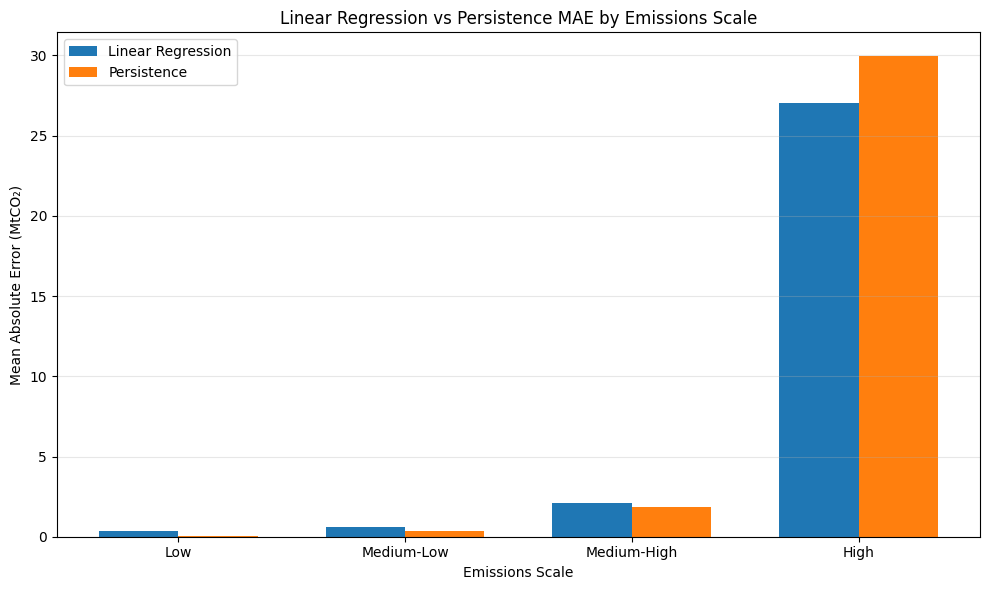

In [123]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = emission_scale_summary.copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    plot_df["Linear_MAE"],
    width,
    label="Linear Regression"
)

plt.bar(
    x + width/2,
    plot_df["Persistence_MAE"],
    width,
    label="Persistence"
)

plt.xticks(
    x,
    plot_df["Emission_Scale"]
)

plt.xlabel("Emissions Scale")
plt.ylabel("Mean Absolute Error (MtCO₂)")
plt.title(
    "Linear Regression vs Persistence MAE by Emissions Scale"
)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

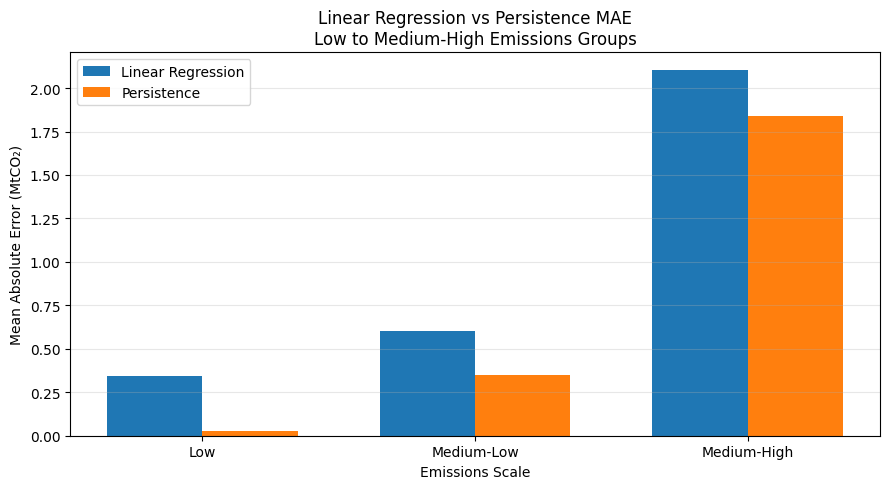

In [124]:
small_scale_df = emission_scale_summary[
    emission_scale_summary["Emission_Scale"] != "High"
].copy()

x = np.arange(len(small_scale_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    small_scale_df["Linear_MAE"],
    width,
    label="Linear Regression"
)

plt.bar(
    x + width/2,
    small_scale_df["Persistence_MAE"],
    width,
    label="Persistence"
)

plt.xticks(
    x,
    small_scale_df["Emission_Scale"]
)

plt.xlabel("Emissions Scale")
plt.ylabel("Mean Absolute Error (MtCO₂)")
plt.title(
    "Linear Regression vs Persistence MAE\nLow to Medium-High Emissions Groups"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Emissions-Scale Visualization

The comparison shows that absolute forecast errors increase substantially with emissions scale. Persistence produces lower MAE in the low, medium-low, and medium-high groups, while Linear Regression produces lower MAE in the highest-emission group.

The large difference in error magnitude between the highest-emission group and the remaining groups also demonstrates why aggregate error metrics are strongly influenced by major emitters.